# 06b: Model Architectures

This is one of six notebooks covering the deep-learning (FNN/LSTM/TCN) side of this thesis:

- `06a_sequence_investigation.ipynb` -- jobs-per-user distribution, the sequence-length choice, padding policy, the sequence-construction leakage test, and F-DATA/PM100 lag-1 autocorrelation; also holds the deep-learning feature-set explanation shared by the notebooks below.
- `06b_model_architectures.ipynb` -- the FNN/SequenceLSTM/SequenceTCN/`_CausalConvBlock`/FlatDataset/SequenceDataset class definitions, documented layer by layer, an equivalence check against `src/models.py`, architecture diagrams, the training configuration, and a checkpoint-match check across all 18 (combination, architecture) pairs.
- `06c_dl_power.ipynb` -- the real FNN/LSTM/TCN sweep for F-DATA power and PM100 power.
- `06d_dl_duration.ipynb` -- the same for F-DATA duration and PM100 duration.
- `06e_dl_memory.ipynb` -- the same for F-DATA memory and PM100 memory (`pm100_memory_c4`).
- `06f_dl_comparison.ipynb` -- the F-DATA duration/memory raw-space collapse diagnostic (including the three-user inspection), the same-features classical-ML control, and the six-combination summary against classical ML.

What `src/models.py`'s FNN, SequenceLSTM, and SequenceTCN actually do, documented from the real
code, real instantiated models, and real data shapes -- not a general description of what an
FNN/LSTM/TCN typically looks like. Every size, count, kernel, dilation, shape, and parameter
number below is read from the actual objects the sweep used. The six classes below are defined
fresh, in this notebook's own namespace, copied verbatim from `src/models.py` -- not imported
from it -- and an equivalence check proves the two copies behave identically. See
`06a_sequence_investigation.ipynb` for the deep-learning feature-set explanation (why
`current_dim` differs from classical ML's own feature count) and the sequence-length/padding
decisions this section's models build on.

In [1]:
import warnings
warnings.filterwarnings("ignore", message="IProgress not found")

import sys
sys.path.append("..")

import pathlib

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import torch
import torch.nn as nn
from IPython.display import display

from src import models, scaling
from src.dl_pipeline import prepare_combo_data, load_dim_table, CKPT_DIR, MAX_EPOCHS, PATIENCE, BATCH_SIZE

pd.set_option("display.width", 160)
FIGURES_DIR = pathlib.Path("figures")
FIGURES_DIR.mkdir(exist_ok=True)


## Overview

All three architectures share: the same standardized input features (`src/scaling.py`, fit on `tune_train` only), the same log-transformed regression target, the same loss (mean squared error), and a single scalar regression output per job. They differ only in how much of a user's job history they see and how they read it:

- **FNN** sees only the current job's own feature vector -- no history.
- **SequenceLSTM** and **SequenceTCN** see the current job's own feature vector AND the user's past 10 jobs (oldest first, zero-padded for users with less history) -- concatenated with a learned encoding of that history before the output head, so both are "FNN plus history," not history alone.

## Data fed to the models

`FlatDataset` (FNN) and `SequenceDataset` (LSTM/TCN) are the two dataset classes in `src/models.py` that turn the already-standardized feature matrix into model input.

**What a history position holds, concretely**: `SequenceDataset` looks up each history position's own row in the SAME standardized feature matrix the current job uses -- that prior job's own submission-time Tier A feature vector (what it requested, when, as whom), never that prior job's measured outcome (Tier B, excluded by construction). The one exception is the per-user rolling-mean feature (`{target}_user_rolling_mean`, window=5), which IS a lagged average of the target's own past values and therefore does carry target information, deliberately and without leakage (it only ever uses strictly earlier jobs). See `06a_sequence_investigation.ipynb`'s sequence-construction section for the full explanation and the real-sequence padding check this notebook's own checkpoint-match section relies on.

In [2]:
from torch.utils.data import Dataset


class FlatDataset(Dataset):
    """FNN input: one row's flat Tier A feature vector -> its (log-space)
    target. X is a 2D float32 array (n_rows, n_features)."""

    def __init__(self, X: np.ndarray, y: np.ndarray):
        self.X = torch.as_tensor(X, dtype=torch.float32)
        self.y = torch.as_tensor(y, dtype=torch.float32)

    def __len__(self) -> int:
        return len(self.y)

    def __getitem__(self, idx):
        return self.X[idx], self.y[idx]


class SequenceDataset(Dataset):
    """LSTM/TCN input: gathers each row's SEQ_LEN-length sequence on the
    fly from a flat feature table, using the (seq_idx, mask) pair
    src/sequences.build_sequence_index produces -- avoids ever
    materializing the full (n_rows, SEQ_LEN, n_features) tensor at once
    (prohibitive at F-DATA's scale: ~16.3M rows x 10 x ~95 features x
    4 bytes is ~62GB). X stays a plain float32 numpy array on CPU; only
    one batch's worth of gathered sequences is built and moved to GPU at
    a time, by the training loop's own device-transfer step.

    X is expected to already be standardized (src/scaling.py) before
    reaching this class -- after standardization, a real feature value can
    legitimately land near 0, which would be indistinguishable from a
    zero-filled padding position without an explicit signal. The mask is
    therefore appended as an EXTRA channel (1.0 = real position, 0.0 =
    padding) on every timestep, so the sequence's per-timestep dimension is
    n_features + 1, not n_features -- a padded position can never look like
    an average real job just because standardization centers the data near
    zero.

    Also returns the TARGET row's own scaled feature vector (current,
    plain n_features wide, no mask channel) alongside the sequence --
    LSTM/TCN need this directly (see SequenceLSTM's docstring: the
    sequence alone never contains the current job's own features, by
    construction, since it only gathers strictly-prior jobs)."""

    def __init__(self, X: np.ndarray, y: np.ndarray, seq_idx: np.ndarray, mask: np.ndarray):
        self.X = np.asarray(X, dtype=np.float32)
        self.y = torch.as_tensor(y, dtype=torch.float32)
        self.seq_idx = seq_idx
        self.mask = mask
        self.n_features = self.X.shape[1]

    def __len__(self) -> int:
        return len(self.y)

    def __getitem__(self, idx):
        idx_row = self.seq_idx[idx]        # (SEQ_LEN,), -1 where padded
        mask_row = self.mask[idx]          # (SEQ_LEN,), bool
        seq = np.zeros((len(idx_row), self.n_features + 1), dtype=np.float32)
        real = idx_row[mask_row]
        seq[mask_row, :self.n_features] = self.X[real]
        seq[:, self.n_features] = mask_row.astype(np.float32)  # mask channel: 1.0 real, 0.0 pad
        current = self.X[idx]              # the TARGET row's own scaled features
        return torch.from_numpy(seq), torch.from_numpy(current), self.y[idx]



### One real sample from each dataset class (PM100 power)

`prepare_combo_data` (`src/dl_pipeline.py`, shared with notebooks 06c/06d/06e and the original sweep script) is imported above; calling it here, for PM100 power only (fast: PM100's full pipeline, including sequence construction, takes seconds), pulls the exact same objects the sweep used for that combination.

In [3]:
arch_example = prepare_combo_data("pm100_power")

flat_ds = FlatDataset(
    scaling.apply_scaler(arch_example["X_full_df"], arch_example["scaler_params"]),
    arch_example["y_full"])
seq_ds = SequenceDataset(arch_example["X_scaled_full"], arch_example["y_full"],
                                 arch_example["seq_idx"], arch_example["mask"])

flat_x, flat_y = flat_ds[0]
print("FlatDataset[0]:")
print(f"  x: type={type(flat_x).__name__}, shape={tuple(flat_x.shape)}, dtype={flat_x.dtype} "
      f"-- one row's flat standardized feature vector")
print(f"  y: type={type(flat_y).__name__}, shape={tuple(flat_y.shape)}, dtype={flat_y.dtype} "
      f"-- the log-space target, a scalar")

seq_x, seq_cur, seq_y = seq_ds[0]
print("\nSequenceDataset[0]:")
print(f"  seq: type={type(seq_x).__name__}, shape={tuple(seq_x.shape)}, dtype={seq_x.dtype} "
      f"-- (seq_len=10, n_features+1); axis 0 is the 10 history slots oldest-to-most-recent, "
      f"axis 1 is the standardized feature vector plus one extra mask channel (1.0=real, 0.0=padding)")
print(f"  current: type={type(seq_cur).__name__}, shape={tuple(seq_cur.shape)}, "
      f"dtype={seq_cur.dtype} -- the TARGET row's own standardized feature vector (no mask "
      f"channel, since it is never padding)")
print(f"  y: type={type(seq_y).__name__}, shape={tuple(seq_y.shape)}, dtype={seq_y.dtype}")


[pm100] excluded 22.0% of jobs as non-completed (50928 / 231238)


pm100_power: 126,217 train / 54,093 test rows; scaler log-transformed 7/28 columns; sequences built in 2s, fill rate 71.58%
FlatDataset[0]:
  x: type=Tensor, shape=(28,), dtype=torch.float32 -- one row's flat standardized feature vector
  y: type=Tensor, shape=(), dtype=torch.float32 -- the log-space target, a scalar

SequenceDataset[0]:
  seq: type=Tensor, shape=(10, 29), dtype=torch.float32 -- (seq_len=10, n_features+1); axis 0 is the 10 history slots oldest-to-most-recent, axis 1 is the standardized feature vector plus one extra mask channel (1.0=real, 0.0=padding)
  current: type=Tensor, shape=(28,), dtype=torch.float32 -- the TARGET row's own standardized feature vector (no mask channel, since it is never padding)
  y: type=Tensor, shape=(), dtype=torch.float32


### Padding made concrete: one user with a full history, one without

Sequence position 0 is the oldest of the 10 history slots; a user with fewer than 10 prior jobs gets zero-padding in the EARLY slots (left-padded), with mask=False marking exactly those positions -- confirmed directly below on two real rows, not asserted from the docstring alone.

In [4]:
mask = arch_example["mask"]
seq_idx = arch_example["seq_idx"]
n_real = mask.sum(axis=1)

partial_row = int(np.where((n_real > 0) & (n_real < 10))[0][0])
full_row = int(np.where(n_real == 10)[0][0])

def render_sequence_table(row, label):
    print(f"{label}: target row {row}")
    rows_out = []
    for k in range(10):
        if mask[row, k]:
            src_row = int(seq_idx[row, k])
            rows_out.append(dict(slot=k, real=True, source_row=src_row))
        else:
            rows_out.append(dict(slot=k, real=False, source_row=None))
    display(pd.DataFrame(rows_out).set_index("slot"))

render_sequence_table(partial_row, "Partial history (padding visible in early slots)")
render_sequence_table(full_row, "Full history (all 10 slots real)")


Partial history (padding visible in early slots): target row 11


,real,source_row
slot,,
0,False,NaN
1,False,NaN
2,False,NaN
3,False,NaN
4,False,NaN
5,False,NaN
6,True,7351.0
7,True,7290.0
8,True,6854.0


Full history (all 10 slots real): target row 0


,real,source_row
slot,,
0,True,457
1,True,76
2,True,383
3,True,440
4,True,442
5,True,476
6,True,714
7,True,999
8,True,1058


### Feature dimension per combination

`current_dim` (the standardized feature count) and `history_dim` (`current_dim + 1` for the mask channel) for all six combinations, read from `data/interim/notebook06_results/dim_table.csv` -- written by notebooks 06c/06d/06e, each contributing the rows for the combinations they ran (so this notebook never needs to reload F-DATA/PM100 itself just to read off a feature count). Raises a clear error naming the producing notebook if any rows are missing.

In [5]:
dim_df = load_dim_table()
display(dim_df)


,current_dim,history_dim
combo,,
fdata_power,93,94
fdata_duration,95,96
fdata_memory,93,94
pm100_power,28,29
pm100_duration,28,29
pm100_memory_c4,22,23


### A shared tracing helper

Registers a forward hook on every leaf module (no children) of a real instantiated model, records its class, its real constructor arguments (read off the module's own attributes, not retyped), and the real input/output tensor shapes from one real forward pass. Used below for each architecture's layer-by-layer shapes, and again for the architecture diagrams.

In [6]:
def describe_module(name, m):
    cls = type(m).__name__
    parts = []
    if isinstance(m, nn.Linear):
        parts.append(f"in_features={m.in_features}, out_features={m.out_features}")
    elif isinstance(m, nn.LSTM):
        parts.append(f"input_size={m.input_size}, hidden_size={m.hidden_size}, "
                      f"num_layers={m.num_layers}, bidirectional={m.bidirectional}, "
                      f"dropout={m.dropout}")
    elif isinstance(m, nn.Conv1d):
        parts.append(f"in_channels={m.in_channels}, out_channels={m.out_channels}, "
                      f"kernel_size={m.kernel_size[0]}, dilation={m.dilation[0]}, "
                      f"padding={m.padding[0]}")
    elif isinstance(m, nn.Dropout):
        parts.append(f"p={m.p}")
    detail = ", ".join(parts)
    return f"{name} ({cls}{': ' + detail if detail else ''})"


def _shape_of(x):
    if torch.is_tensor(x):
        return tuple(x.shape)
    if isinstance(x, (tuple, list)):
        return [_shape_of(e) for e in x]
    return None


def trace_model(model, *inputs):
    """Real execution order, from real forward hooks -- not a hand-typed layer list."""
    records = []
    handles = []

    def make_hook(name, m):
        def hook(module, inp, out):
            records.append(dict(name=name, module=m, label=describe_module(name, m),
                                 in_shapes=[_shape_of(t) for t in inp if torch.is_tensor(t)],
                                 out_shape=_shape_of(out)))
        return hook

    leaf_modules = [(n, m) for n, m in model.named_modules() if len(list(m.children())) == 0]
    for n, m in leaf_modules:
        handles.append(m.register_forward_hook(make_hook(n, m)))
    model.eval()
    with torch.no_grad():
        model(*inputs)
    for h in handles:
        h.remove()
    return records


def count_params(model):
    total = sum(p.numel() for p in model.parameters())
    trainable = sum(p.numel() for p in model.parameters() if p.requires_grad)
    return total, trainable


## FNN

Source, directly from `src/models.py`:

In [7]:
class FNN(nn.Module):
    """Plain feedforward network on the flat Tier A feature set -- the same
    features the classical ML models (05/05b/05c) use, no sequence input.
    Three hidden layers (256/256/128) with ReLU + dropout; a single linear
    output unit for regression in log-space (matching the classical models'
    own target transform)."""

    def __init__(self, input_dim: int, hidden: tuple[int, int, int] = (256, 256, 128),
                 dropout: float = 0.1):
        super().__init__()
        h1, h2, h3 = hidden
        self.net = nn.Sequential(
            nn.Linear(input_dim, h1), nn.ReLU(), nn.Dropout(dropout),
            nn.Linear(h1, h2), nn.ReLU(), nn.Dropout(dropout),
            nn.Linear(h2, h3), nn.ReLU(),
            nn.Linear(h3, 1),
        )

    def forward(self, x: torch.Tensor) -> torch.Tensor:
        return self.net(x).squeeze(-1)



Layer by layer, from the source above (`hidden=(256, 256, 128)` is the default, unchanged by the sweep):

| Layer | Type | In -> Out | Activation | Dropout | Normalization |
|---|---|---|---|---|---|
| `net.0` | Linear | `input_dim` -> 256 | ReLU (`net.1`) | 0.1 (`net.2`) | none |
| `net.3` | Linear | 256 -> 256 | ReLU (`net.4`) | 0.1 (`net.5`) | none |
| `net.6` | Linear | 256 -> 128 | ReLU (`net.7`) | **none** | none |
| `net.8` | Linear (output head) | 128 -> 1 | none (raw regression output) | none | none |

No batch normalization or layer normalization anywhere in the network -- `src/models.py`'s `FNN.__init__` builds only `nn.Linear`/`nn.ReLU`/`nn.Dropout` layers, confirmed directly from the source printed above. Dropout is applied after the first two hidden layers only; the third hidden layer's ReLU output goes straight into the output head with no dropout -- not a general FNN convention, just what this code does.

In [8]:
print("Distinct current_dim values across the six combinations:",
      sorted(dim_df["current_dim"].unique()))

fnn_param_rows = []
for dim in sorted(int(d) for d in dim_df["current_dim"].unique()):
    combos_sharing = list(dim_df[dim_df["current_dim"] == dim].index)
    model = FNN(input_dim=dim)
    total, trainable = count_params(model)
    fnn_param_rows.append(dict(current_dim=dim, combinations=", ".join(combos_sharing),
                                total_params=total, trainable_params=trainable))
display(pd.DataFrame(fnn_param_rows).set_index("current_dim"))


Distinct current_dim values across the six combinations: [np.int64(22), np.int64(28), np.int64(93), np.int64(95)]


,combinations,total_params,trainable_params
current_dim,,,
22,pm100_memory_c4,104705,104705
28,"pm100_power, pm100_duration",106241,106241
93,"fdata_power, fdata_memory",122881,122881
95,fdata_duration,123393,123393


### FNN dummy forward pass (real batch, real shapes at every stage)

In [9]:
fnn_dim = int(dim_df.loc["pm100_power", "current_dim"])
fnn_demo = FNN(input_dim=fnn_dim)
fnn_batch = torch.randn(4, fnn_dim)
for rec in trace_model(fnn_demo, fnn_batch):
    print(f"{rec['label']}: in={rec['in_shapes']} -> out={rec['out_shape']}")


net.0 (Linear: in_features=28, out_features=256): in=[(4, 28)] -> out=(4, 256)
net.1 (ReLU): in=[(4, 256)] -> out=(4, 256)
net.2 (Dropout: p=0.1): in=[(4, 256)] -> out=(4, 256)
net.3 (Linear: in_features=256, out_features=256): in=[(4, 256)] -> out=(4, 256)
net.4 (ReLU): in=[(4, 256)] -> out=(4, 256)
net.5 (Dropout: p=0.1): in=[(4, 256)] -> out=(4, 256)
net.6 (Linear: in_features=256, out_features=128): in=[(4, 256)] -> out=(4, 128)
net.7 (ReLU): in=[(4, 128)] -> out=(4, 128)
net.8 (Linear: in_features=128, out_features=1): in=[(4, 128)] -> out=(4, 1)


## SequenceLSTM

Source, directly from `src/models.py`:

In [10]:
class SequenceLSTM(nn.Module):
    """A user's past SEQ_LEN jobs (each job's own Tier A feature vector,
    oldest first, zero-padded at the front for users with less history --
    see src/sequences.py) through a 2-layer LSTM, PLUS the current (target)
    job's own scaled feature vector, concatenated with the LSTM's final
    hidden state before the output head -- i.e. FNN plus history, not
    history alone.

    Found and fixed as a real bug, not a design choice made up front:
    build_sequence_index only ever gathers STRICTLY PRIOR jobs (by
    construction, to avoid leakage -- confirmed directly, sampling 5 real
    rows and checking that a target row's own index never appears in its
    own sequence). That is correct for the sequence itself, but earlier
    versions of this model then saw ONLY that history and nothing else --
    the current job's own resource request, size, and other submission-time
    characteristics never reached the model at all, which is most of what
    FNN uses to get R2=0.905 (log-space, PM100 power) against LSTM-without-
    current-features' R2=0.276 on the identical data. Concatenating the
    current job's own features back in (the history encoding augments them,
    rather than being the model's only information) is the fix."""

    def __init__(self, history_dim: int, current_dim: int, hidden: int = 128,
                 num_layers: int = 2, dropout: float = 0.1):
        super().__init__()
        self.lstm = nn.LSTM(history_dim, hidden, num_layers=num_layers, batch_first=True,
                             dropout=dropout if num_layers > 1 else 0.0)
        self.head = nn.Linear(hidden + current_dim, 1)

    def forward(self, seq: torch.Tensor, current: torch.Tensor) -> torch.Tensor:
        # seq: (batch, seq_len, history_dim); current: (batch, current_dim)
        out, _ = self.lstm(seq)
        last = out[:, -1, :]
        combined = torch.cat([last, current], dim=-1)
        return self.head(combined).squeeze(-1)



Answered directly from the source above, not from a general LSTM description:

- **Hidden size**: 128 (`hidden=128` default).
- **Number of layers**: 2 (`num_layers=2` default).
- **Bidirectional**: no -- `nn.LSTM` is constructed with no `bidirectional` argument, so it keeps PyTorch's own default, `False`.
- **Dropout**: 0.1, applied by `nn.LSTM` itself between its two layers (`dropout=dropout if num_layers > 1 else 0.0` -- PyTorch's LSTM dropout applies to the output of every layer except the last, and only takes effect when `num_layers > 1`, which is the case here).
- **How the mask channel is used**: only as an extra INPUT channel, not as an explicit skip/mask mechanism. `self.lstm(seq)` runs over all 10 timesteps unconditionally -- there is no `pack_padded_sequence` call and no masked attention; the model has no architectural signal beyond the mask channel's own value (1.0 real / 0.0 padding) to distinguish real history from padding, and must learn to use it.
- **Which output is taken**: `out[:, -1, :]` -- the top layer's output at the last timestep (position 9). Left-padding means position 9 is the MOST RECENT real position whenever one exists, but it is NOT guaranteed to be real just because the user has prior jobs by count: `06a_sequence_investigation.ipynb`'s real-sequence verification finds position 9 is still padding for about 49% of F-DATA jobs and 47% of PM100 jobs that do have at least one prior job by count, because `src/sequences.build_sequence_index`'s strict-time check excludes a candidate position whenever it shares the target job's own submit timestamp -- common enough, from batch/near-simultaneous submissions, to affect roughly half of all non-first jobs on both datasets. When position 9 is padding, the model correctly receives an all-zero, mask=0 vector there, not a wrong answer -- just a less informative input than "the last timestep is always real" would suggest.
- **History/current fusion**: concatenation -- `torch.cat([last, current], dim=-1)` -- then a single linear head over the concatenated vector. Not an attention mechanism, not a gating mechanism.
- **Output head**: `nn.Linear(hidden + current_dim, 1)` -- one linear layer, no activation, straight to the scalar regression output.

In [11]:
lstm_dim = int(dim_df.loc["pm100_power", "current_dim"])
lstm_demo = SequenceLSTM(history_dim=lstm_dim + 1, current_dim=lstm_dim)
lstm_seq_batch = torch.randn(4, 10, lstm_dim + 1)
lstm_cur_batch = torch.randn(4, lstm_dim)
for rec in trace_model(lstm_demo, lstm_seq_batch, lstm_cur_batch):
    print(f"{rec['label']}: in={rec['in_shapes']} -> out={rec['out_shape']}")

lstm_param_rows = []
for dim in sorted(int(d) for d in dim_df["current_dim"].unique()):
    combos_sharing = list(dim_df[dim_df["current_dim"] == dim].index)
    model = SequenceLSTM(history_dim=dim + 1, current_dim=dim)
    total, trainable = count_params(model)
    lstm_param_rows.append(dict(current_dim=dim, combinations=", ".join(combos_sharing),
                                 total_params=total, trainable_params=trainable))
display(pd.DataFrame(lstm_param_rows).set_index("current_dim"))


lstm (LSTM: input_size=29, hidden_size=128, num_layers=2, bidirectional=False, dropout=0.1): in=[(4, 10, 29)] -> out=[(4, 10, 128), [(2, 4, 128), (2, 4, 128)]]
head (Linear: in_features=156, out_features=1): in=[(4, 156)] -> out=(4, 1)


,combinations,total_params,trainable_params
current_dim,,,
22,pm100_memory_c4,210583,210583
28,"pm100_power, pm100_duration",213661,213661
93,"fdata_power, fdata_memory",247006,247006
95,fdata_duration,248032,248032


## SequenceTCN

Source, directly from `src/models.py` (`_CausalConvBlock`, the residual block, then `SequenceTCN` itself):

In [12]:
class _CausalConvBlock(nn.Module):
    """One dilated-causal-convolution residual block (Bai et al. 2018's TCN
    pattern, simplified): two causal conv1d + ReLU + dropout layers, plus a
    1x1 residual projection when the channel count changes. Causal padding
    (pad the LEFT only, by (kernel_size-1)*dilation, then trim any
    right-side overhang) keeps position t's output a function of positions
    <= t only -- the same "no future leakage" property src/sequences.py's
    build_sequence_index already enforces at the data level, preserved here
    at the architecture level too."""

    def __init__(self, in_channels: int, out_channels: int, kernel_size: int,
                 dilation: int, dropout: float):
        super().__init__()
        pad = (kernel_size - 1) * dilation
        # Plain Conv1d (weight_norm tried and removed): an unnormalized first-pass
        # implementation diverged to loss values of 1e13-1e14, weight_norm alone only
        # partially helped (faster recovery from the initial blow-up, but still plateaued
        # ~10 orders of magnitude above baseline after 20 epochs) -- the real root cause was
        # unscaled input features (see src/scaling.py), not the conv layers' own normalization.
        self.conv1 = nn.Conv1d(in_channels, out_channels, kernel_size, padding=pad,
                                dilation=dilation)
        self.conv2 = nn.Conv1d(out_channels, out_channels, kernel_size, padding=pad,
                                dilation=dilation)
        self.pad = pad
        self.relu = nn.ReLU()
        self.dropout = nn.Dropout(dropout)
        self.downsample = (nn.Conv1d(in_channels, out_channels, 1)
                            if in_channels != out_channels else None)

    def _trim(self, x: torch.Tensor) -> torch.Tensor:
        return x[:, :, :-self.pad] if self.pad > 0 else x

    def forward(self, x: torch.Tensor) -> torch.Tensor:
        out = self.dropout(self.relu(self._trim(self.conv1(x))))
        out = self.dropout(self.relu(self._trim(self.conv2(out))))
        res = x if self.downsample is None else self.downsample(x)
        return self.relu(out + res)


class SequenceTCN(nn.Module):
    """Same sequence input as SequenceLSTM (batch, seq_len, history_dim),
    transposed to (batch, history_dim, seq_len) for Conv1d. 4 levels of
    dilated causal convolution (dilation 1/2/4/8, two conv layers per level
    at that level's dilation -- receptive field 61 at kernel_size=3,
    computed as 1 + sum over every conv layer of (kernel_size-1)*dilation,
    read directly from the real instantiated model's own Conv1d modules,
    not estimated by hand -- comfortably covers SEQ_LEN=10), channel width
    64 throughout after the first block. PLUS the current job's own scaled
    feature vector, concatenated with the final timestep's channel vector
    before the output head -- same FNN-plus-history fix as SequenceLSTM,
    same reason (see SequenceLSTM's docstring for the full finding)."""

    def __init__(self, history_dim: int, current_dim: int, channels: int = 64, levels: int = 4,
                 kernel_size: int = 3, dropout: float = 0.1):
        super().__init__()
        blocks = []
        in_ch = history_dim
        for level in range(levels):
            blocks.append(_CausalConvBlock(in_ch, channels, kernel_size,
                                            dilation=2 ** level, dropout=dropout))
            in_ch = channels
        self.blocks = nn.Sequential(*blocks)
        self.head = nn.Linear(channels + current_dim, 1)

    def forward(self, seq: torch.Tensor, current: torch.Tensor) -> torch.Tensor:
        # seq: (batch, seq_len, history_dim) -> (batch, history_dim, seq_len)
        out = self.blocks(seq.transpose(1, 2))
        last = out[:, :, -1]
        combined = torch.cat([last, current], dim=-1)
        return self.head(combined).squeeze(-1)



## Notebook-class vs `src.models` equivalence check

The six classes above were just defined fresh, in this notebook's own namespace, copied verbatim from `src/models.py` -- not imported from it. Every cell below this point uses these notebook classes (`FNN`, `SequenceLSTM`, `SequenceTCN`, `_CausalConvBlock`, `FlatDataset`, `SequenceDataset`), not `models.FNN` etc. `src/models.py` itself is untouched -- `scripts/notebook06_deep_learning/run_sweep_pair.py`, `src/dl_pipeline.py` (used by notebooks 06c/06d/06e), and the saved checkpoints all still depend on it exactly as before.

This cell checks the two copies actually behave identically, not just that they look identical: for each architecture (FNN, LSTM, TCN), for each of the four distinct `current_dim` values across the six combinations, it builds both the notebook class and the `src.models` class, confirms their `state_dict` keys and shapes match, copies the notebook model's weights into the `src.models` model, and runs both on the same real batch (gathered via `prepare_combo_data`, reusing `arch_example` for the dim already loaded above and loading one representative combo per remaining dim).

In [13]:
def real_batch(data, n=8):
    """A real batch of FNN/LSTM/TCN inputs, built the same way run_pair's own
    build_loaders does -- standardized flat features, and standardized sequences plus the
    current row's own standardized features -- from one prepared combo's data."""
    flat_X = scaling.apply_scaler(data["X_full_df"], data["scaler_params"])
    flat_ds_local = FlatDataset(flat_X, data["y_full"])
    seq_ds_local = SequenceDataset(data["X_scaled_full"], data["y_full"],
                                    data["seq_idx"], data["mask"])
    flat_x = torch.stack([flat_ds_local[i][0] for i in range(n)])
    seq_x = torch.stack([seq_ds_local[i][0] for i in range(n)])
    seq_cur = torch.stack([seq_ds_local[i][1] for i in range(n)])
    return flat_x, seq_x, seq_cur


# One representative combo per distinct current_dim (the other combos sharing that dim
# have the identical feature count, so the equivalence check itself does not depend on
# which one is picked).
dim_to_combo = {int(dim): dim_df[dim_df["current_dim"] == dim].index[0]
                for dim in sorted(dim_df["current_dim"].unique())}

_combo_batch_cache = {}
equivalence_rows = []
for dim, combo in dim_to_combo.items():
    if combo not in _combo_batch_cache:
        data = arch_example if combo == "pm100_power" else prepare_combo_data(combo)
        _combo_batch_cache[combo] = real_batch(data)
    flat_x, seq_x, seq_cur = _combo_batch_cache[combo]

    arch_specs = [
        ("FNN", FNN(input_dim=dim), models.FNN(input_dim=dim), (flat_x,)),
        ("LSTM", SequenceLSTM(history_dim=dim + 1, current_dim=dim),
         models.SequenceLSTM(history_dim=dim + 1, current_dim=dim), (seq_x, seq_cur)),
        ("TCN", SequenceTCN(history_dim=dim + 1, current_dim=dim),
         models.SequenceTCN(history_dim=dim + 1, current_dim=dim), (seq_x, seq_cur)),
    ]
    for arch, nb_model, src_model, batch in arch_specs:
        nb_keys, src_keys = nb_model.state_dict(), src_model.state_dict()
        keys_match = set(nb_keys.keys()) == set(src_keys.keys())
        shapes_match = all(nb_keys[k].shape == src_keys[k].shape for k in nb_keys)
        src_model.load_state_dict(nb_keys)  # same weights into both
        nb_model.eval()
        src_model.eval()
        with torch.no_grad():
            out_nb = nb_model(*batch)
            out_src = src_model(*batch)
        outputs_allclose = bool(torch.allclose(out_nb, out_src))
        nb_total, _ = count_params(nb_model)
        src_total, _ = count_params(src_model)
        equivalence_rows.append(dict(arch=arch, current_dim=dim, combo=combo,
                                      keys_match=keys_match, shapes_match=shapes_match,
                                      outputs_allclose=outputs_allclose,
                                      params_match=nb_total == src_total))

equivalence_df = pd.DataFrame(equivalence_rows).set_index(["arch", "current_dim"])
all_pass = bool(equivalence_df[["keys_match", "shapes_match", "outputs_allclose",
                                 "params_match"]].all().all())
print(f"{len(equivalence_df)} (architecture, current_dim) checks run -- all passed: {all_pass}")
display(equivalence_df)


pm100_memory_c4: 126,217 train / 54,093 test rows; scaler log-transformed 4/22 columns; sequences built in 2s, fill rate 71.58%


[fdata] excluded 9.9% of jobs as non-completed (2558519 / 25866900)


fdata_power: 16,315,866 train / 6,992,514 test rows; scaler log-transformed 10/93 columns; sequences built in 517s, fill rate 75.74%


fdata_duration: 16,315,867 train / 6,992,514 test rows; scaler log-transformed 12/95 columns; sequences built in 515s, fill rate 75.74%


12 (architecture, current_dim) checks run -- all passed: True


,,combo,keys_match,shapes_match,outputs_allclose,params_match
arch,current_dim,,,,,
FNN,22,pm100_memory_c4,True,True,True,True
LSTM,22,pm100_memory_c4,True,True,True,True
TCN,22,pm100_memory_c4,True,True,True,True
FNN,28,pm100_power,True,True,True,True
LSTM,28,pm100_power,True,True,True,True
TCN,28,pm100_power,True,True,True,True
FNN,93,fdata_power,True,True,True,True
LSTM,93,fdata_power,True,True,True,True
TCN,93,fdata_power,True,True,True,True


Answered directly from the source above:

- **Number of blocks**: 4 (`levels=4` default).
- **Channels**: 64 throughout, after the first block maps the input's `history_dim` to 64 (`channels=64` default).
- **Kernel size**: 3 (`kernel_size=3` default), used by every `Conv1d` in every block.
- **Dilation per level**: `2 ** level` for `level in range(4)` -- 1, 2, 4, 8.
- **Padding type**: causal, not symmetric -- `pad = (kernel_size - 1) * dilation` is applied via `Conv1d`'s own symmetric `padding=pad` argument (which pads both sides equally), and `_trim` then removes the resulting right-side overhang (`x[:, :, :-self.pad]`), leaving a net LEFT-only pad -- so position `t`'s output is a function of input positions `<= t` only, confirmed directly from `_trim`'s slicing, not assumed from the class's docstring.
- **Activation**: ReLU, after each conv (and again after the residual add).
- **Dropout**: 0.1, after each conv's ReLU (two dropout applications per block, one after each of the block's two convs).
- **Normalization**: none -- no `BatchNorm`/`LayerNorm`/`weight_norm` anywhere in `_CausalConvBlock` or `SequenceTCN`, confirmed directly from the source above (a `weight_norm` attempt is documented as tried and removed in a comment in the source, not currently part of the architecture).

In [14]:
def tcn_receptive_field(model):
    """Real receptive field, read from the ACTUAL instantiated model's own Conv1d modules
    (kernel_size, dilation) -- not computed by hand from the architecture's stated defaults,
    so this cannot silently drift from what the code actually builds."""
    rf = 1
    layers = []
    for name, m in model.named_modules():
        if isinstance(m, nn.Conv1d) and m.kernel_size[0] > 1:  # excludes 1x1 downsample convs
            contribution = (m.kernel_size[0] - 1) * m.dilation[0]
            rf += contribution
            layers.append((name, m.kernel_size[0], m.dilation[0], contribution))
    return rf, layers

tcn_dim_probe = SequenceTCN(history_dim=29, current_dim=28)
rf, layers = tcn_receptive_field(tcn_dim_probe)
print("Per-layer (name, kernel_size, dilation, receptive-field contribution):")
for l in layers:
    print(f"  {l}")
print(f"\nTotal receptive field: {rf} time steps, vs SEQ_LEN=10")
print(f"Covers the full 10-step history: {rf >= 10}")


Per-layer (name, kernel_size, dilation, receptive-field contribution):
  ('blocks.0.conv1', 3, 1, 2)
  ('blocks.0.conv2', 3, 1, 2)
  ('blocks.1.conv1', 3, 2, 4)
  ('blocks.1.conv2', 3, 2, 4)
  ('blocks.2.conv1', 3, 4, 8)
  ('blocks.2.conv2', 3, 4, 8)
  ('blocks.3.conv1', 3, 8, 16)
  ('blocks.3.conv2', 3, 8, 16)

Total receptive field: 61 time steps, vs SEQ_LEN=10
Covers the full 10-step history: True


**Contradiction found and corrected**: `src/models.py`'s `SequenceTCN` docstring, before this check, stated "receptive field 15 at kernel_size=3". The real computation above -- walking the actual instantiated model's own `Conv1d` modules, not estimating by hand -- gives **61**, not 15. The error in the original docstring came from summing only the four dilations (1+2+4+8=15) without multiplying by `(kernel_size-1)=2` and without counting that each block has TWO convolution layers at its dilation, not one. The qualitative conclusion the docstring drew ("comfortably covers SEQ_LEN=10") still holds -- 61 is well over 10 -- but the number itself was wrong and has been corrected in the source.

In [15]:
tcn_dim = int(dim_df.loc["pm100_power", "current_dim"])
tcn_demo = SequenceTCN(history_dim=tcn_dim + 1, current_dim=tcn_dim)
tcn_seq_batch = torch.randn(4, 10, tcn_dim + 1)
tcn_cur_batch = torch.randn(4, tcn_dim)
for rec in trace_model(tcn_demo, tcn_seq_batch, tcn_cur_batch):
    print(f"{rec['label']}: in={rec['in_shapes']} -> out={rec['out_shape']}")

tcn_param_rows = []
for dim in sorted(int(d) for d in dim_df["current_dim"].unique()):
    combos_sharing = list(dim_df[dim_df["current_dim"] == dim].index)
    model = SequenceTCN(history_dim=dim + 1, current_dim=dim)
    total, trainable = count_params(model)
    tcn_param_rows.append(dict(current_dim=dim, combinations=", ".join(combos_sharing),
                                total_params=total, trainable_params=trainable))
display(pd.DataFrame(tcn_param_rows).set_index("current_dim"))


blocks.0.conv1 (Conv1d: in_channels=29, out_channels=64, kernel_size=3, dilation=1, padding=2): in=[(4, 29, 10)] -> out=(4, 64, 12)
blocks.0.relu (ReLU): in=[(4, 64, 10)] -> out=(4, 64, 10)
blocks.0.dropout (Dropout: p=0.1): in=[(4, 64, 10)] -> out=(4, 64, 10)
blocks.0.conv2 (Conv1d: in_channels=64, out_channels=64, kernel_size=3, dilation=1, padding=2): in=[(4, 64, 10)] -> out=(4, 64, 12)
blocks.0.relu (ReLU): in=[(4, 64, 10)] -> out=(4, 64, 10)
blocks.0.dropout (Dropout: p=0.1): in=[(4, 64, 10)] -> out=(4, 64, 10)
blocks.0.downsample (Conv1d: in_channels=29, out_channels=64, kernel_size=1, dilation=1, padding=0): in=[(4, 29, 10)] -> out=(4, 64, 10)
blocks.0.relu (ReLU): in=[(4, 64, 10)] -> out=(4, 64, 10)
blocks.1.conv1 (Conv1d: in_channels=64, out_channels=64, kernel_size=3, dilation=2, padding=4): in=[(4, 64, 10)] -> out=(4, 64, 14)
blocks.1.relu (ReLU): in=[(4, 64, 10)] -> out=(4, 64, 10)
blocks.1.dropout (Dropout: p=0.1): in=[(4, 64, 10)] -> out=(4, 64, 10)
blocks.1.conv2 (Conv1d

,combinations,total_params,trainable_params
current_dim,,,
22,pm100_memory_c4,92567,92567
28,"pm100_power, pm100_duration",94109,94109
93,"fdata_power, fdata_memory",110814,110814
95,fdata_duration,111328,111328


Reading the shapes above: each `Conv1d`'s own raw output (before trimming) is longer than its input along the time axis (causal padding adds `pad` positions on both sides via `Conv1d`'s own symmetric padding); the following `ReLU`/`Dropout` operate on the TRIMMED tensor (back to length 10), since `_trim` runs between the conv and the activation in `_CausalConvBlock.forward`. The time dimension is reduced to a single vector by taking the LAST timestep across all 64 channels (`out[:, :, -1]`), then concatenated with the current job's own feature vector before the same kind of linear output head as FNN and LSTM.

## Side-by-side summary

In [16]:
summary_rows = []
for arch_name, builder in [("FNN", lambda d: FNN(input_dim=d)),
                            ("LSTM", lambda d: SequenceLSTM(history_dim=d + 1, current_dim=d)),
                            ("TCN", lambda d: SequenceTCN(history_dim=d + 1, current_dim=d))]:
    params_by_dim = {}
    for dim in sorted(int(d) for d in dim_df["current_dim"].unique()):
        total, _ = count_params(builder(dim))
        params_by_dim[dim] = total
    fdata_dims = sorted(dim_df[dim_df.index.str.startswith("fdata")]["current_dim"].unique())
    pm100_dims = sorted(dim_df[dim_df.index.str.startswith("pm100")]["current_dim"].unique())
    fdata_params = ", ".join(f"{d}->{params_by_dim[d]:,}" for d in fdata_dims)
    pm100_params = ", ".join(f"{d}->{params_by_dim[d]:,}" for d in pm100_dims)
    summary_rows.append(dict(
        architecture=arch_name,
        input="current job only" if arch_name == "FNN" else "current job + 10-job history",
        uses_history=(arch_name != "FNN"),
        core_operation={"FNN": "3 Linear+ReLU(+Dropout) layers", "LSTM": "2-layer LSTM",
                         "TCN": "4-level dilated causal Conv1d"}[arch_name],
        hidden_or_channels={"FNN": "256/256/128", "LSTM": "128", "TCN": "64"}[arch_name],
        depth={"FNN": 3, "LSTM": 2, "TCN": 4}[arch_name],
        history_current_fusion="n/a (no history)" if arch_name == "FNN" else "concatenation before output head",
        output_head="Linear(., 1)",
        params_by_fdata_current_dim=fdata_params,
        params_by_pm100_current_dim=pm100_params,
    ))

summary_df = pd.DataFrame(summary_rows).set_index("architecture")
display(summary_df)


,input,uses_history,core_operation,hidden_or_channels,depth,history_current_fusion,output_head,params_by_fdata_current_dim,params_by_pm100_current_dim
architecture,,,,,,,,,
FNN,current job only,False,3 Linear+ReLU(+Dropout) layers,256/256/128,3,n/a (no history),"Linear(., 1)","93->122,881, 95->123,393","22->104,705, 28->106,241"
LSTM,current job + 10-job history,True,2-layer LSTM,128,2,concatenation before output head,"Linear(., 1)","93->247,006, 95->248,032","22->210,583, 28->213,661"
TCN,current job + 10-job history,True,4-level dilated causal Conv1d,64,4,concatenation before output head,"Linear(., 1)","93->110,814, 95->111,328","22->92,567, 28->94,109"


## Architecture diagrams

Generated programmatically from the real instantiated models and real forward-hook shapes -- no hand-typed numbers in the drawing code; every box's label comes from `describe_module`/`trace_model_list`. Drawn with explicit branches, not a single chain, matching each model's own `forward()`:

- **FNN**: a straight chain (no branching) -- labeled input and output added.
- **SequenceLSTM**: `current` does NOT pass through the LSTM -- it is drawn as its own branch straight into the concat node, alongside the LSTM's own output after slicing out the last timestep.
- **SequenceTCN**: each residual block's skip path (1x1 downsample conv in block 0, identity in blocks 1-3, confirmed directly that blocks 1-3 share identical in/out channel counts before collapsing them into one drawing) is its own arrow into an explicit `add` node, followed by `relu` -- not left implicit. Blocks 1-3 are drawn ONCE (not three times), labeled with their three real dilation values (2, 4, 8), since the code confirms they are structurally identical to each other, differing only in dilation.

**Graphviz checked, not available (matplotlib used instead, the stated fallback)**: neither the `dot` binary nor the Python `graphviz` package is installed on this machine, and installing the system Graphviz binary would need `sudo apt install graphviz` -- not done here. The matplotlib branching-diagram function below lays out explicit (x, y) node positions and draws edges exactly matching the real control flow, rather than a generic auto-layout.

One diagram per architecture per DISTINCT `current_dim` (4 values: F-DATA 93, F-DATA 95, PM100 28, PM100 22 -- not one per dataset, same reasoning as before), overwriting the earlier (chain-only) versions of these same files.

In [17]:
import collections
import textwrap


def trace_model_list(model, *inputs):
    """Like trace_model, but a module called more than once in one forward pass (the
    residual block's shared relu/dropout, called once after conv1 and again after conv2)
    gets a separate list entry per call, in call order -- needed to label each call
    correctly in the branching diagrams below."""
    records = collections.defaultdict(list)
    handles = []

    def make_hook(name, m):
        def hook(module, inp, out):
            records[name].append(dict(label=describe_module(name, m),
                                       in_shapes=[_shape_of(t) for t in inp if torch.is_tensor(t)],
                                       out_shape=_shape_of(out)))
        return hook

    leaf_modules = [(n, m) for n, m in model.named_modules() if len(list(m.children())) == 0]
    for n, m in leaf_modules:
        handles.append(m.register_forward_hook(make_hook(n, m)))
    model.eval()
    with torch.no_grad():
        model(*inputs)
    for h in handles:
        h.remove()
    return records


def draw_branching_diagram(nodes, edges, title, save_path, box_w=3.6, box_h=1.0):
    """nodes: dict id -> dict(x, y, text, kind); x/y are grid positions (not inches),
    kind in {"io", "op", "merge", "skip"} only picks a fill color. edges: list of
    (from_id, to_id) -- these encode the REAL branching read off the model's own forward()
    (e.g. current never feeds the LSTM/TCN blocks; a residual block's skip path is its own
    edge into an add node), not inferred from hook call order alone."""
    xs = [n["x"] for n in nodes.values()]
    ys = [n["y"] for n in nodes.values()]
    x_gap, y_gap = 0.6, 1.1
    min_x, max_x = min(xs), max(xs)
    min_y, max_y = min(ys), max(ys)
    width = (max_x - min_x) * (box_w + x_gap) + box_w
    height = (max_y - min_y) * (box_h + y_gap) + box_h
    fig, ax = plt.subplots(figsize=(max(6, width / 1.3 + 1), max(4, height / 1.3 + 1)))

    def pos(nid):
        n = nodes[nid]
        px = (n["x"] - min_x) * (box_w + x_gap)
        py = (max_y - n["y"]) * (box_h + y_gap)
        return px, py

    colors = {"io": "#dde8f5", "op": "#f5ead0", "merge": "#f0d0d0", "skip": "#e4f0d8"}
    for nid, n in nodes.items():
        px, py = pos(nid)
        wrapped_lines = []
        for line in n["text"].split("\n"):
            wrapped_lines.extend(textwrap.wrap(line, width=36) or [""])
        wrapped = "\n".join(wrapped_lines)
        ax.add_patch(plt.Rectangle((px, py - box_h / 2), box_w, box_h,
                                    facecolor=colors.get(n.get("kind", "op"), "#f5ead0"),
                                    edgecolor="black", zorder=2))
        ax.text(px + box_w / 2, py, wrapped, ha="center", va="center", fontsize=6.0, zorder=3)

    for a, b in edges:
        ax1, ay1 = pos(a)
        ax2, ay2 = pos(b)
        start = (ax1 + box_w / 2, ay1 - box_h / 2)
        end = (ax2 + box_w / 2, ay2 + box_h / 2)
        ax.annotate("", xy=end, xytext=start,
                    arrowprops=dict(arrowstyle="->", color="gray", shrinkA=0, shrinkB=0), zorder=1)

    ax.set_xlim(-0.4, width + 0.4)
    ax.set_ylim(-box_h * 0.7, height + box_h * 0.7)
    ax.axis("off")
    ax.set_title(title, fontsize=9)
    fig.tight_layout()
    fig.savefig(save_path, dpi=140, bbox_inches="tight")
    plt.show()
    plt.close(fig)

distinct_dims_with_combos = {int(k): v for k, v in (dim_df.reset_index()
                              .groupby("current_dim")["combo"].apply(list).to_dict()).items()}
print("Distinct current_dim groups:", distinct_dims_with_combos)


Distinct current_dim groups: {22: ['pm100_memory_c4'], 28: ['pm100_power', 'pm100_duration'], 93: ['fdata_power', 'fdata_memory'], 95: ['fdata_duration']}


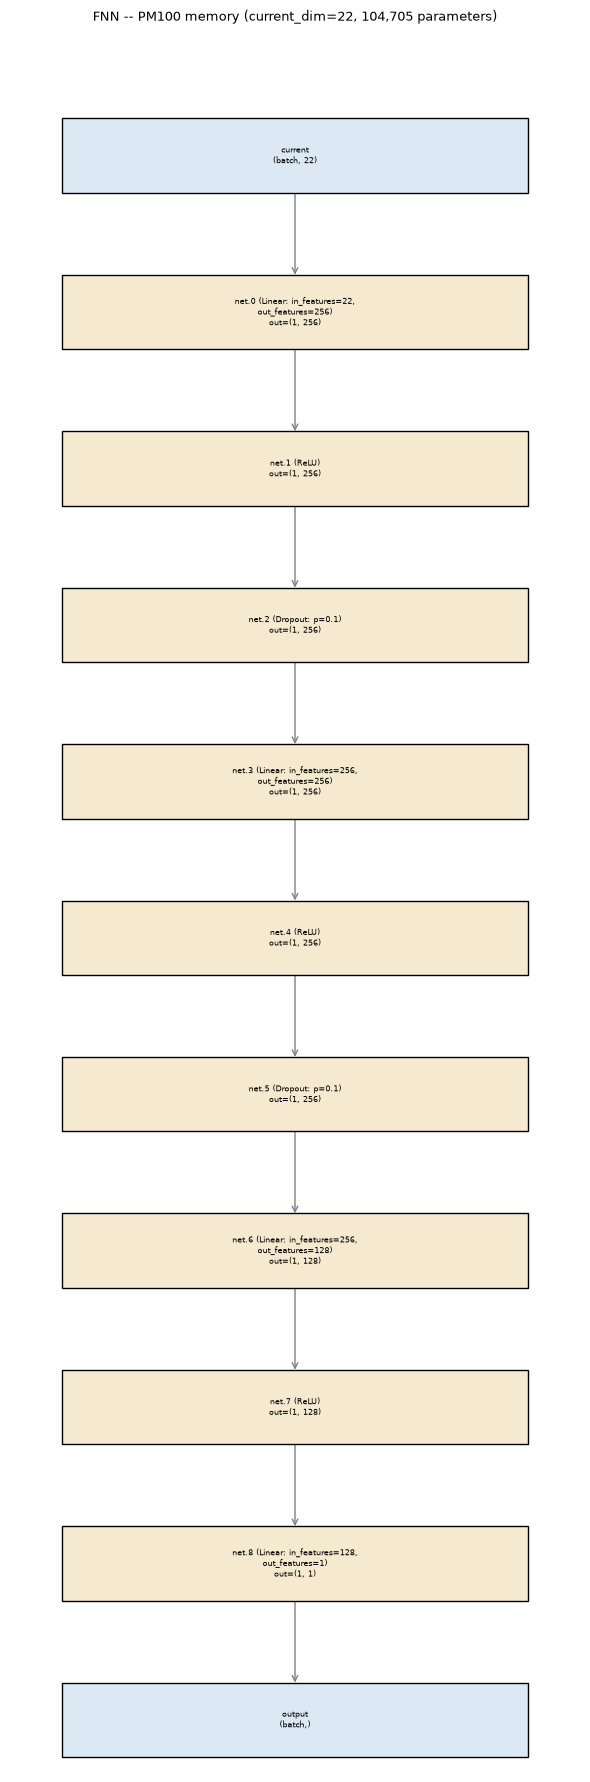

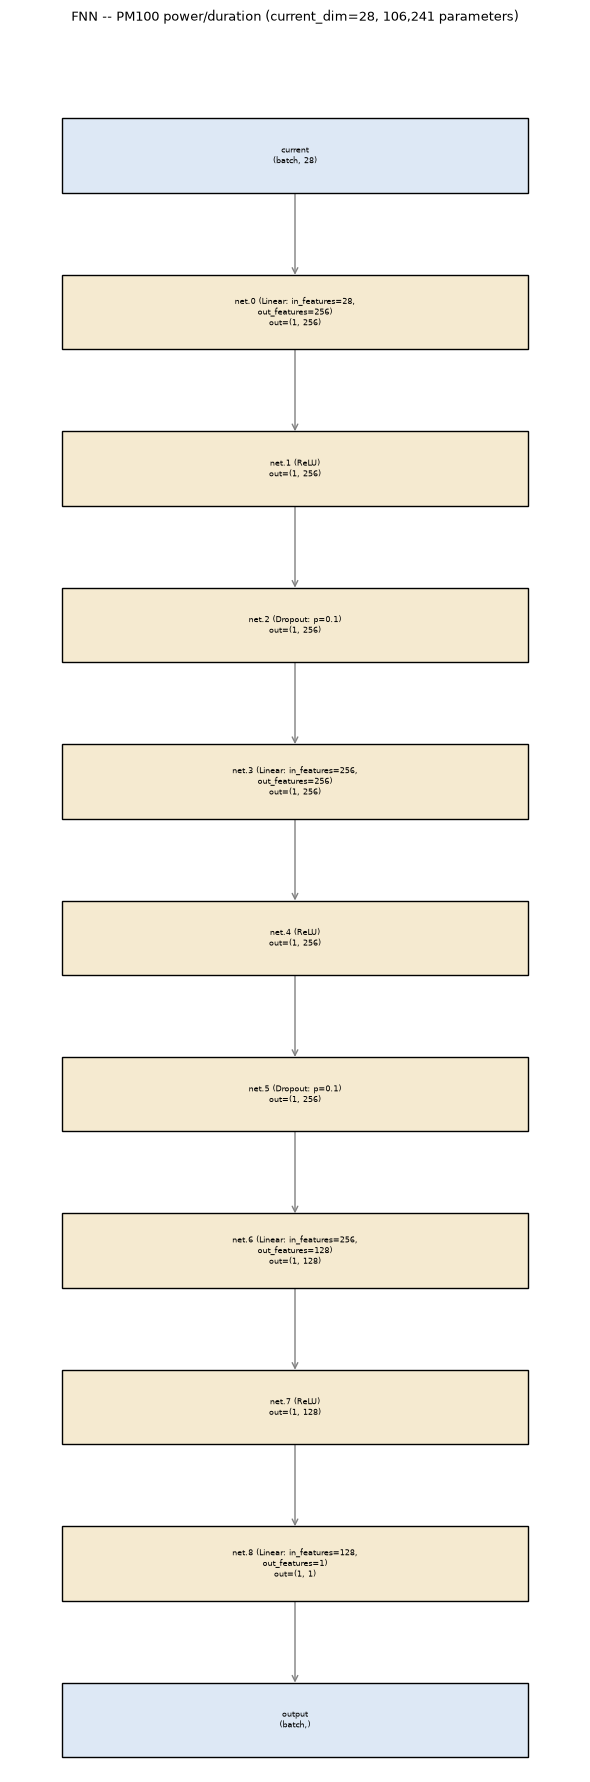

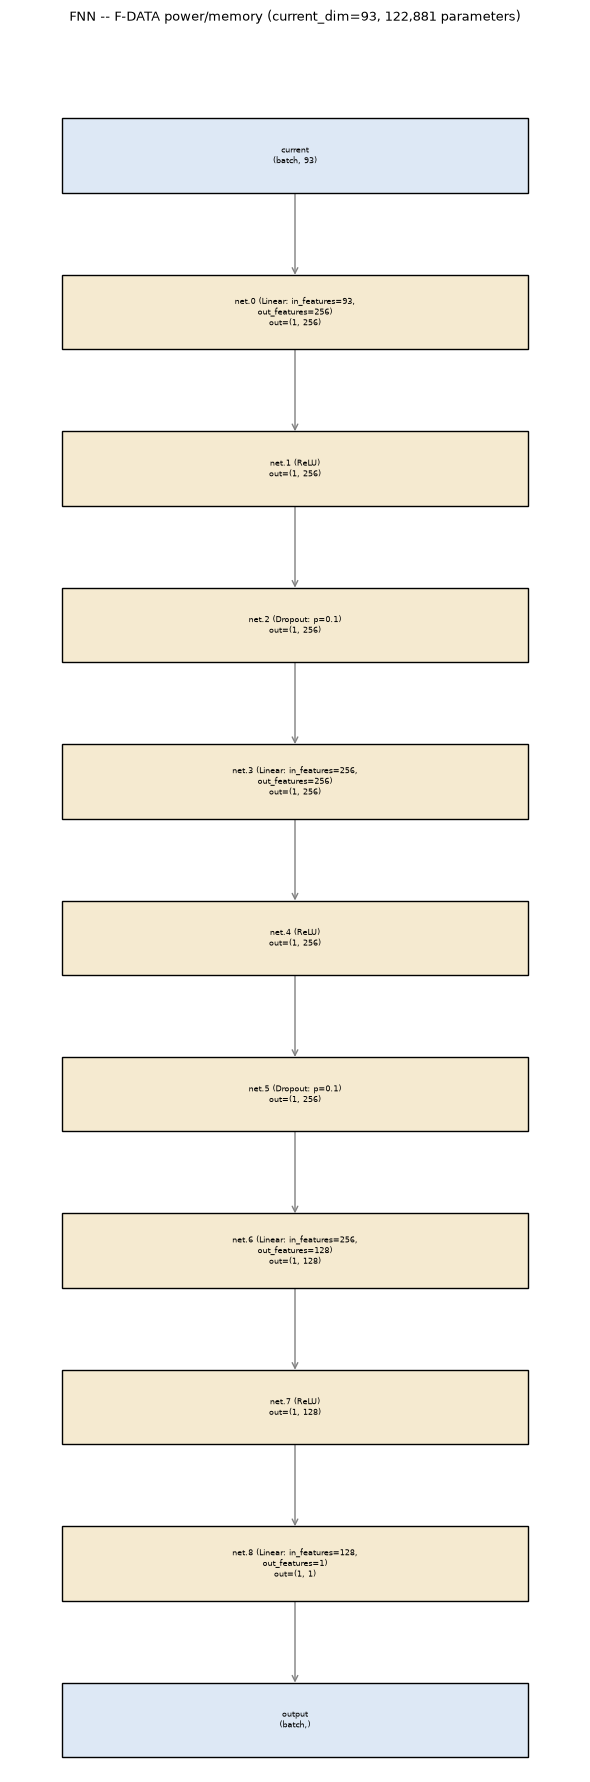

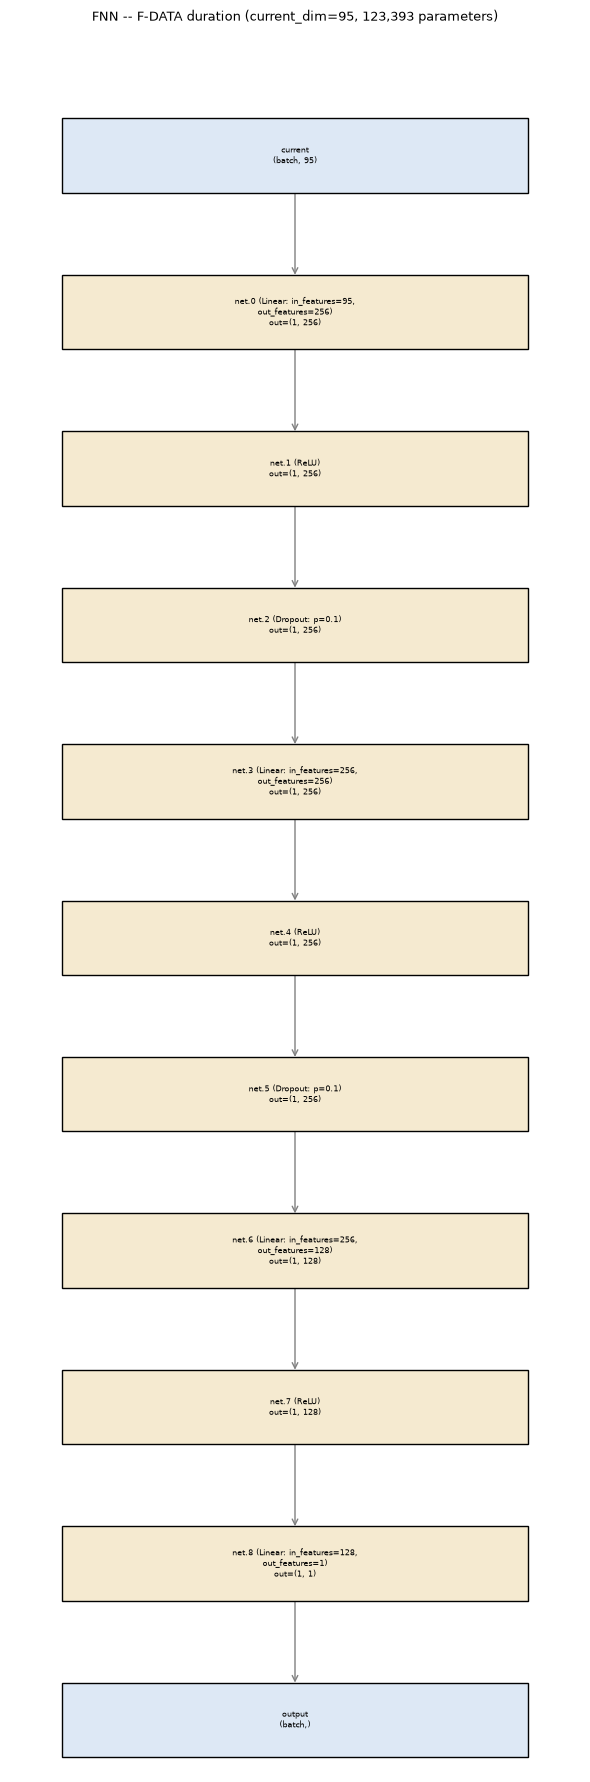

In [18]:
for dim in sorted(int(d) for d in dim_df["current_dim"].unique()):
    combos_sharing = distinct_dims_with_combos[dim]
    dataset_label = "F-DATA" if combos_sharing[0].startswith("fdata") else "PM100"
    combos_text = "/".join(c.replace("fdata_", "").replace("pm100_", "").replace("_c4", "")
                            for c in combos_sharing)

    fnn_model = FNN(input_dim=dim)
    recs = trace_model_list(fnn_model, torch.randn(1, dim))
    total, _ = count_params(fnn_model)

    nodes = {"in": dict(x=0, y=0, kind="io", text=f"current\n(batch, {dim})")}
    edges = []
    prev = "in"
    for i, (name, calls) in enumerate(recs.items()):
        r = calls[0]
        nodes[name] = dict(x=0, y=i + 1, kind="op", text=r["label"] + f"\nout={r['out_shape']}")
        edges.append((prev, name))
        prev = name
    nodes["out"] = dict(x=0, y=len(recs) + 1, kind="io", text="output\n(batch,)")
    edges.append((prev, "out"))

    title = f"FNN -- {dataset_label} {combos_text} (current_dim={dim}, {total:,} parameters)"
    save_path = FIGURES_DIR / f"notebook06_arch_FNN_{dataset_label.lower()}_dim{dim}.png"
    draw_branching_diagram(nodes, edges, title, save_path)


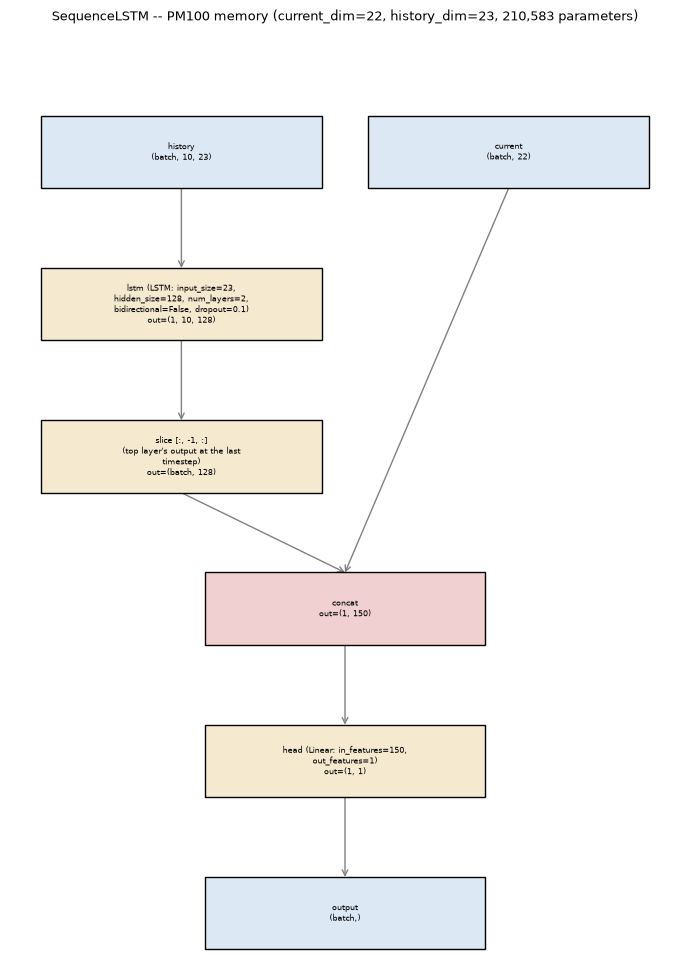

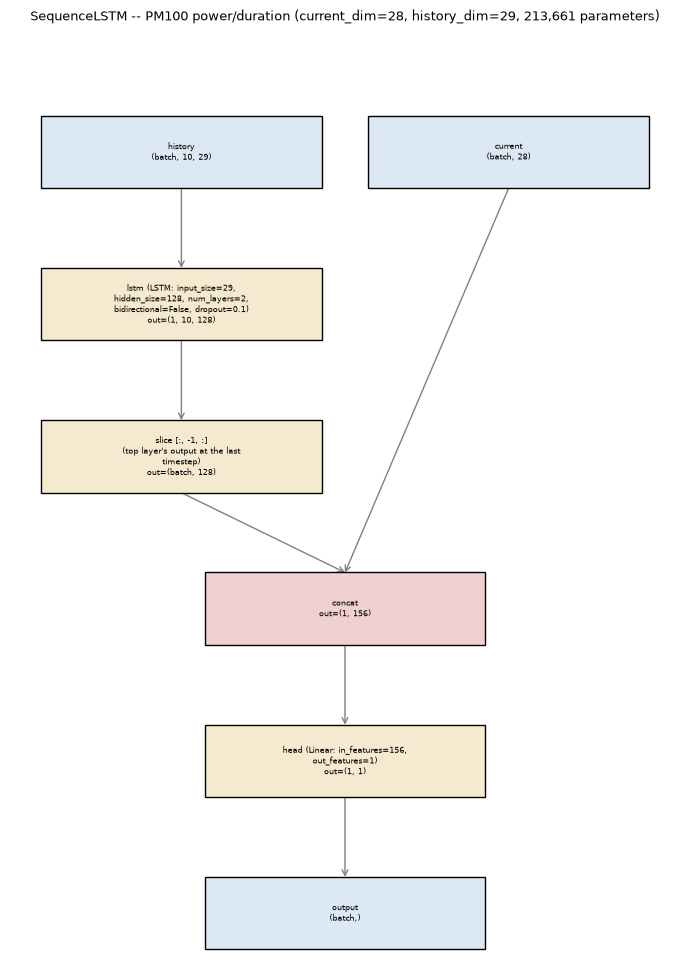

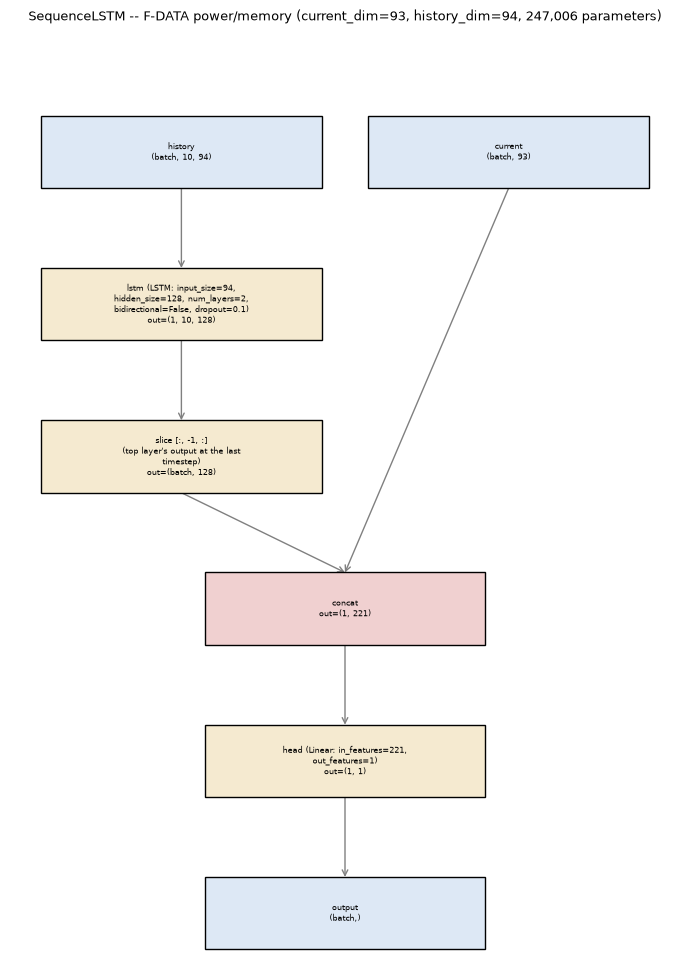

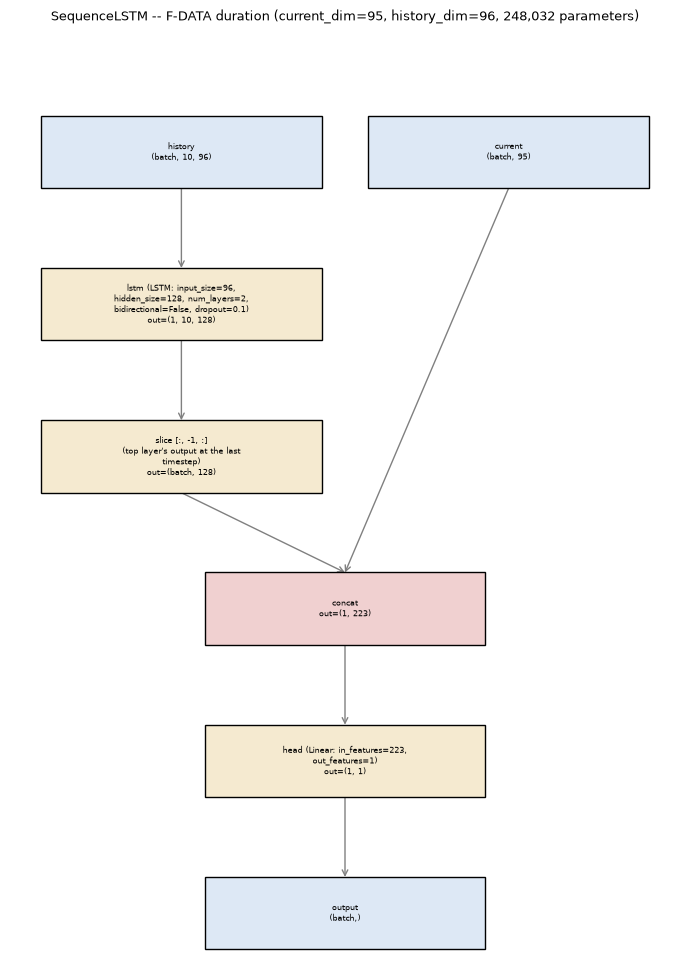

In [19]:
for dim in sorted(int(d) for d in dim_df["current_dim"].unique()):
    combos_sharing = distinct_dims_with_combos[dim]
    dataset_label = "F-DATA" if combos_sharing[0].startswith("fdata") else "PM100"
    combos_text = "/".join(c.replace("fdata_", "").replace("pm100_", "").replace("_c4", "")
                            for c in combos_sharing)

    lstm_model = SequenceLSTM(history_dim=dim + 1, current_dim=dim)
    recs = trace_model_list(lstm_model, torch.randn(1, 10, dim + 1), torch.randn(1, dim))
    total, _ = count_params(lstm_model)
    lstm_out_shape = recs["lstm"][0]["out_shape"][0]  # (batch, 10, hidden) -- the tensor output, not (h_n, c_n)
    hidden = lstm_out_shape[-1]
    head_rec = recs["head"][0]

    nodes = {
        "hist_in": dict(x=0, y=0, kind="io", text=f"history\n(batch, 10, {dim + 1})"),
        "cur_in": dict(x=1, y=0, kind="io", text=f"current\n(batch, {dim})"),
        "lstm": dict(x=0, y=1, kind="op", text=recs["lstm"][0]["label"] + f"\nout={lstm_out_shape}"),
        "slice": dict(x=0, y=2, kind="op", text=f"slice [:, -1, :]\n(top layer's output at the "
                      f"last timestep)\nout=(batch, {hidden})"),
        "concat": dict(x=0.5, y=3, kind="merge", text=f"concat\nout={head_rec['in_shapes'][0]}"),
        "head": dict(x=0.5, y=4, kind="op", text=head_rec["label"] + f"\nout={head_rec['out_shape']}"),
        "out": dict(x=0.5, y=5, kind="io", text="output\n(batch,)"),
    }
    edges = [("hist_in", "lstm"), ("lstm", "slice"), ("slice", "concat"),
             ("cur_in", "concat"), ("concat", "head"), ("head", "out")]

    title = (f"SequenceLSTM -- {dataset_label} {combos_text} (current_dim={dim}, "
             f"history_dim={dim + 1}, {total:,} parameters)")
    save_path = FIGURES_DIR / f"notebook06_arch_LSTM_{dataset_label.lower()}_dim{dim}.png"
    draw_branching_diagram(nodes, edges, title, save_path)


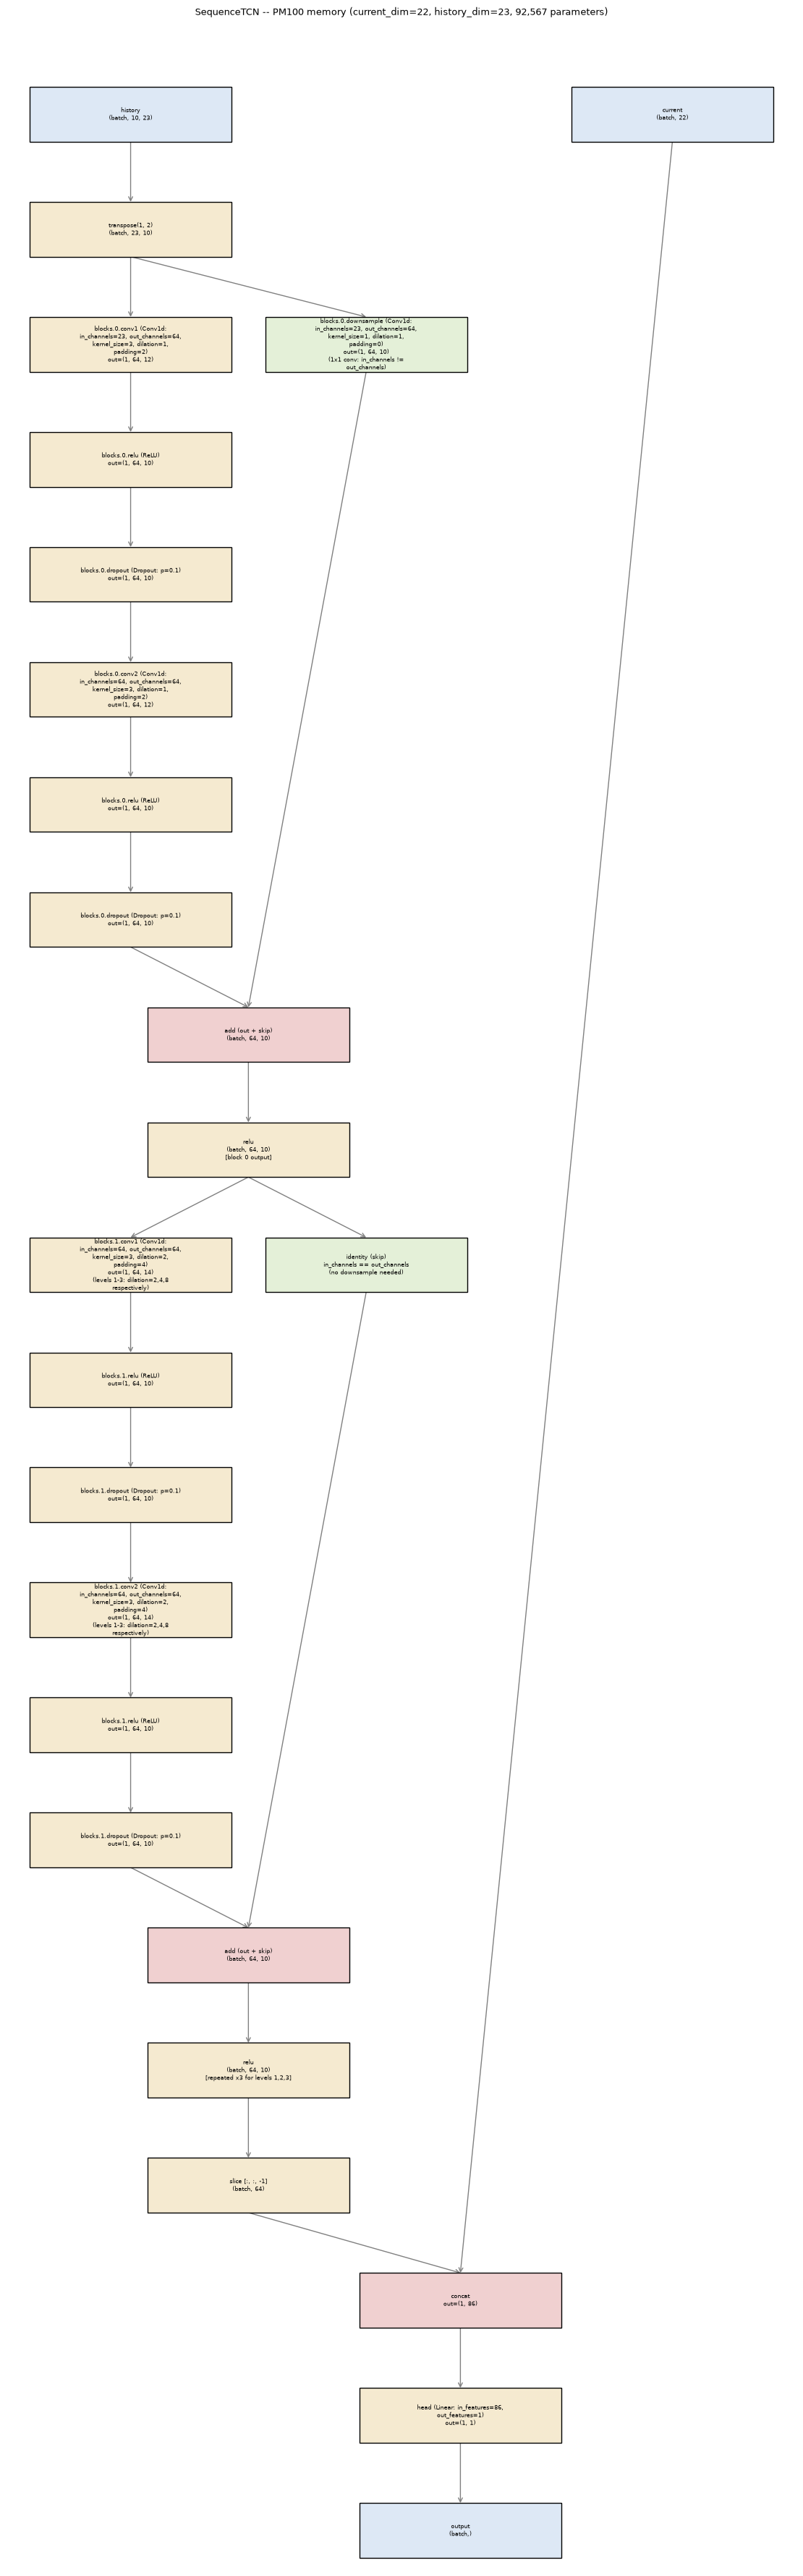

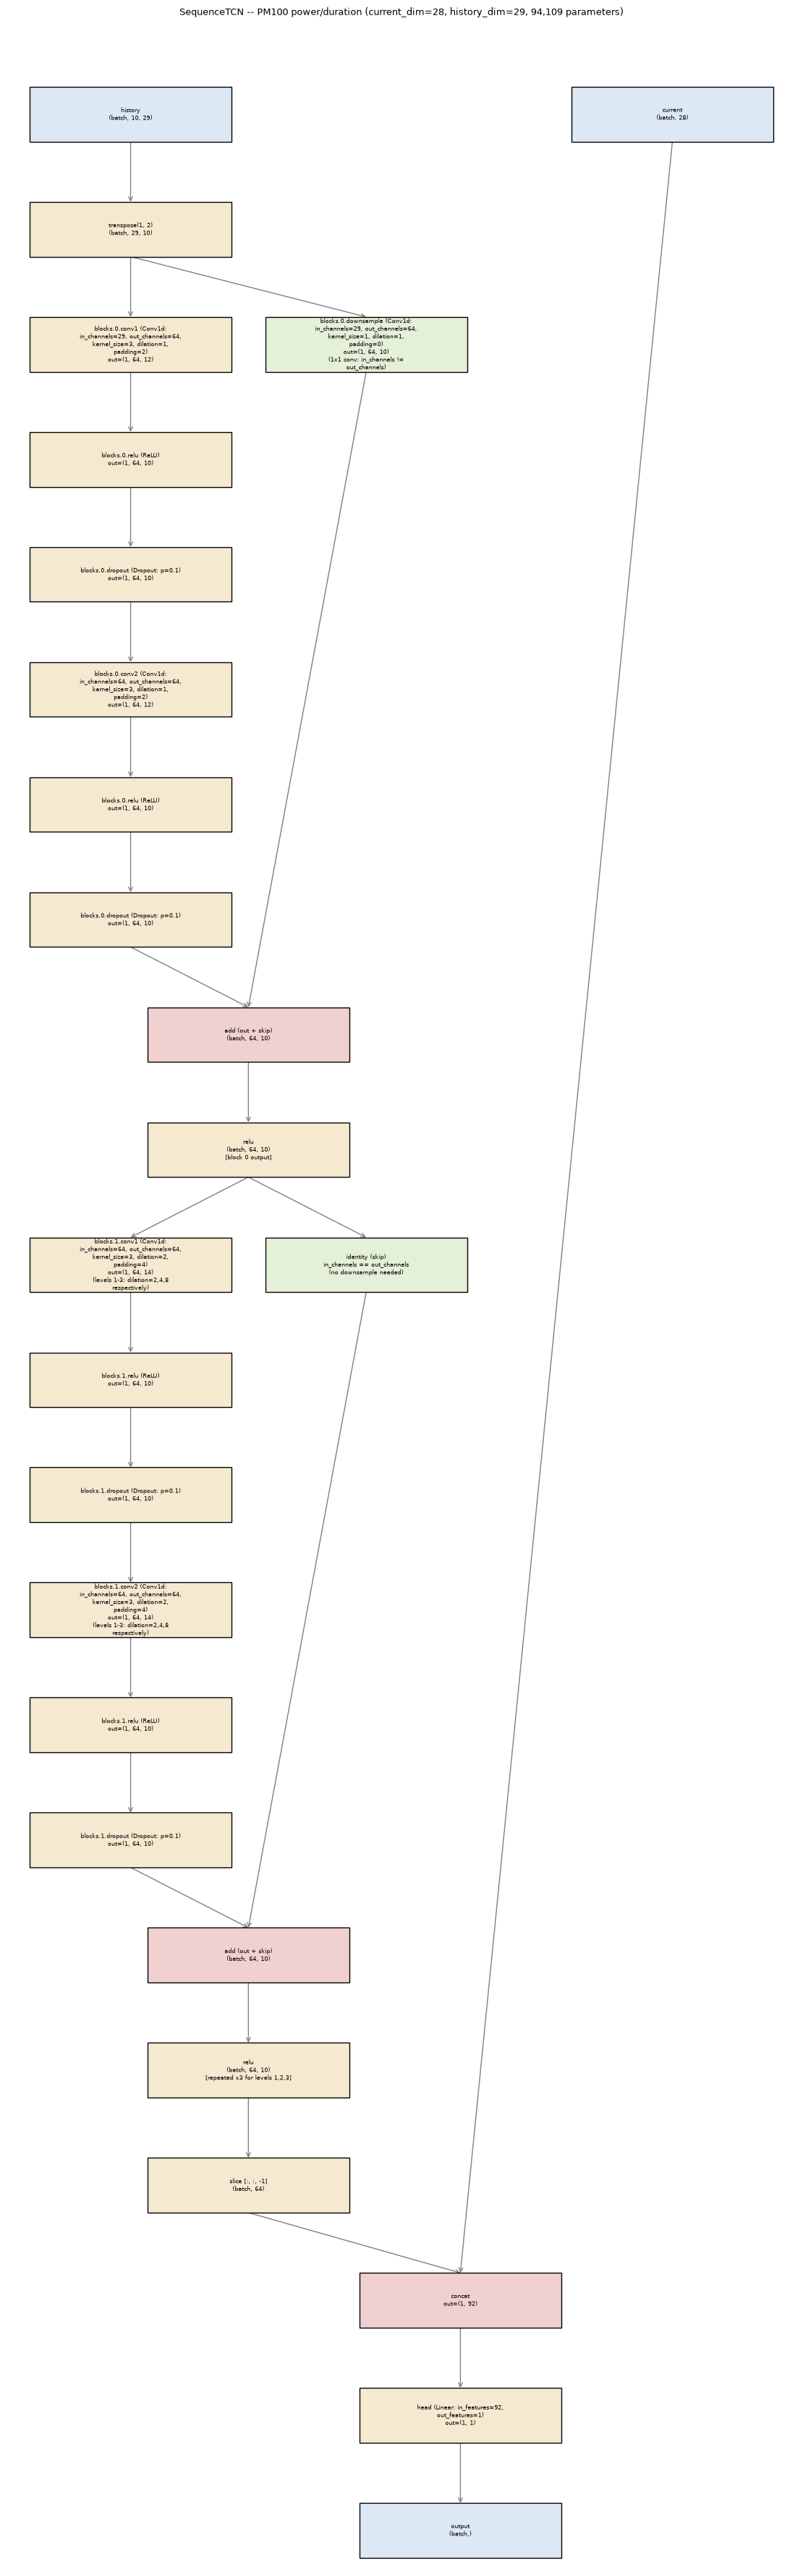

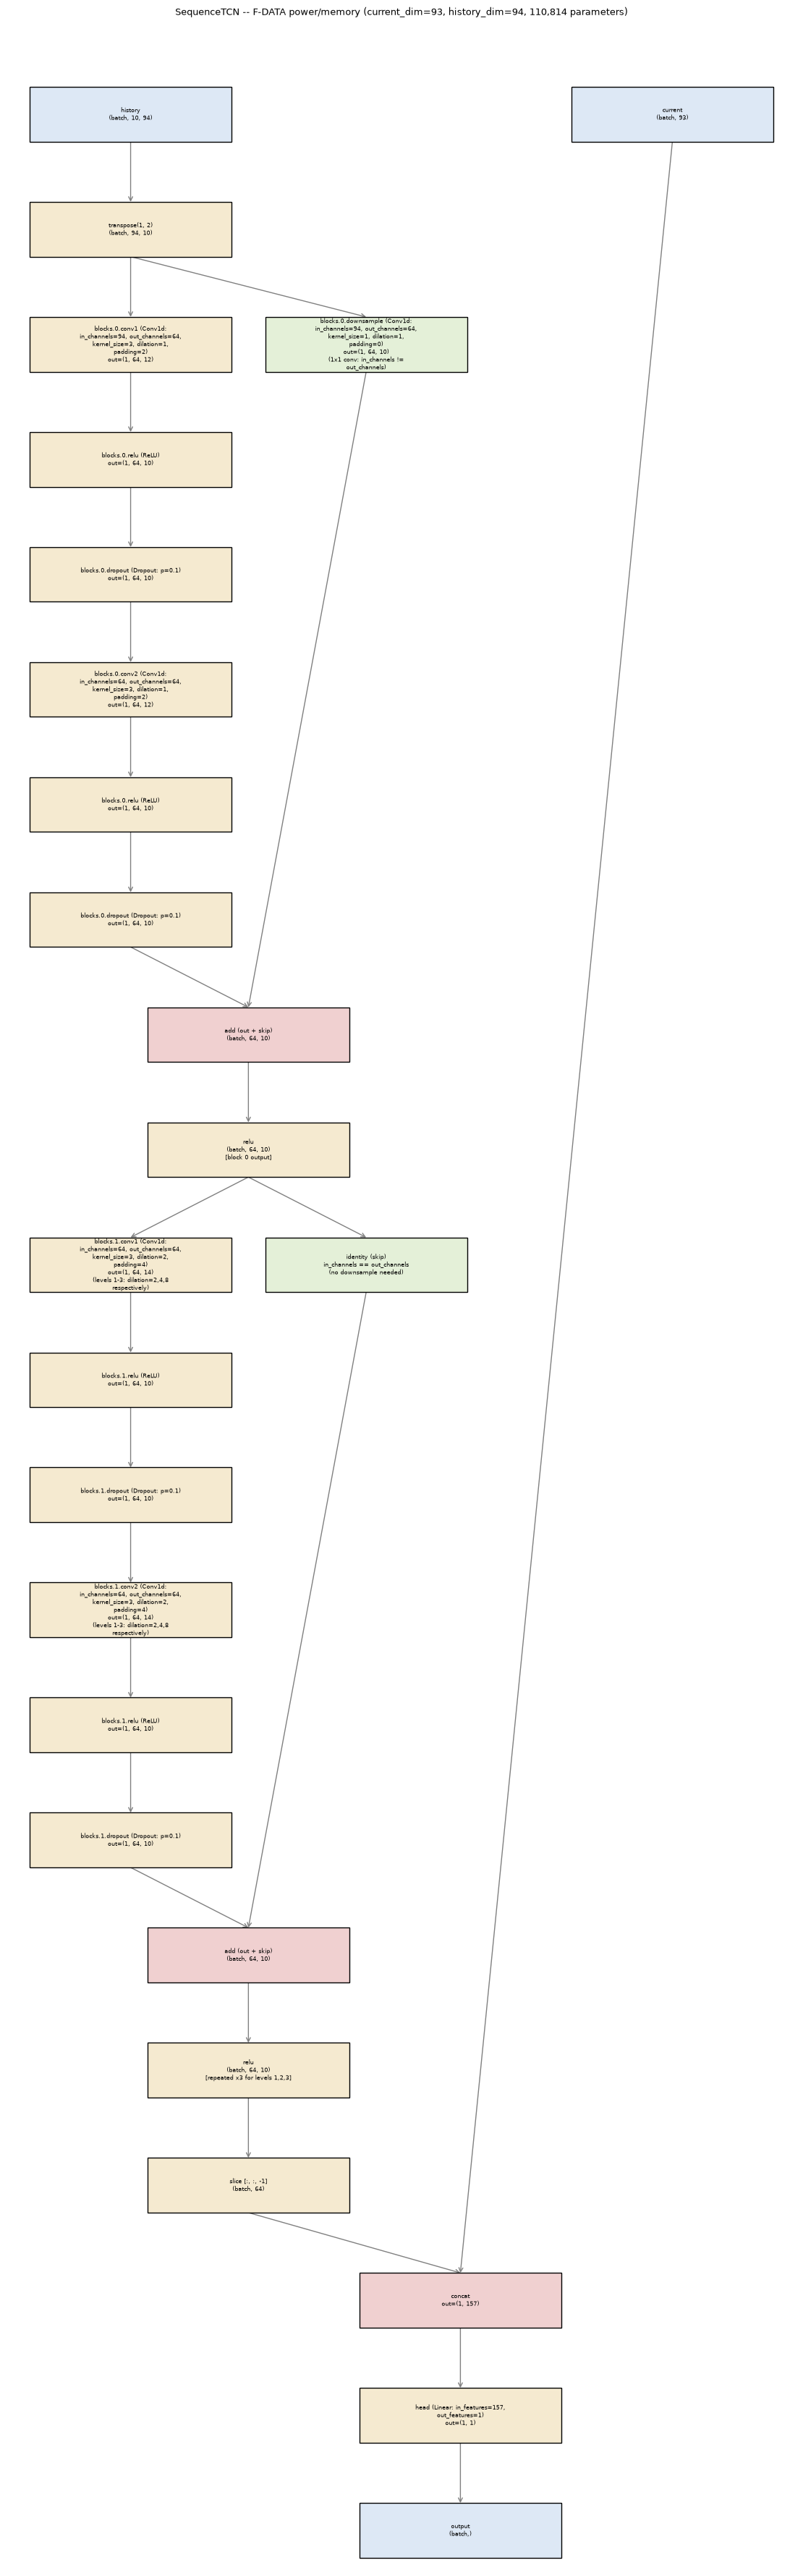

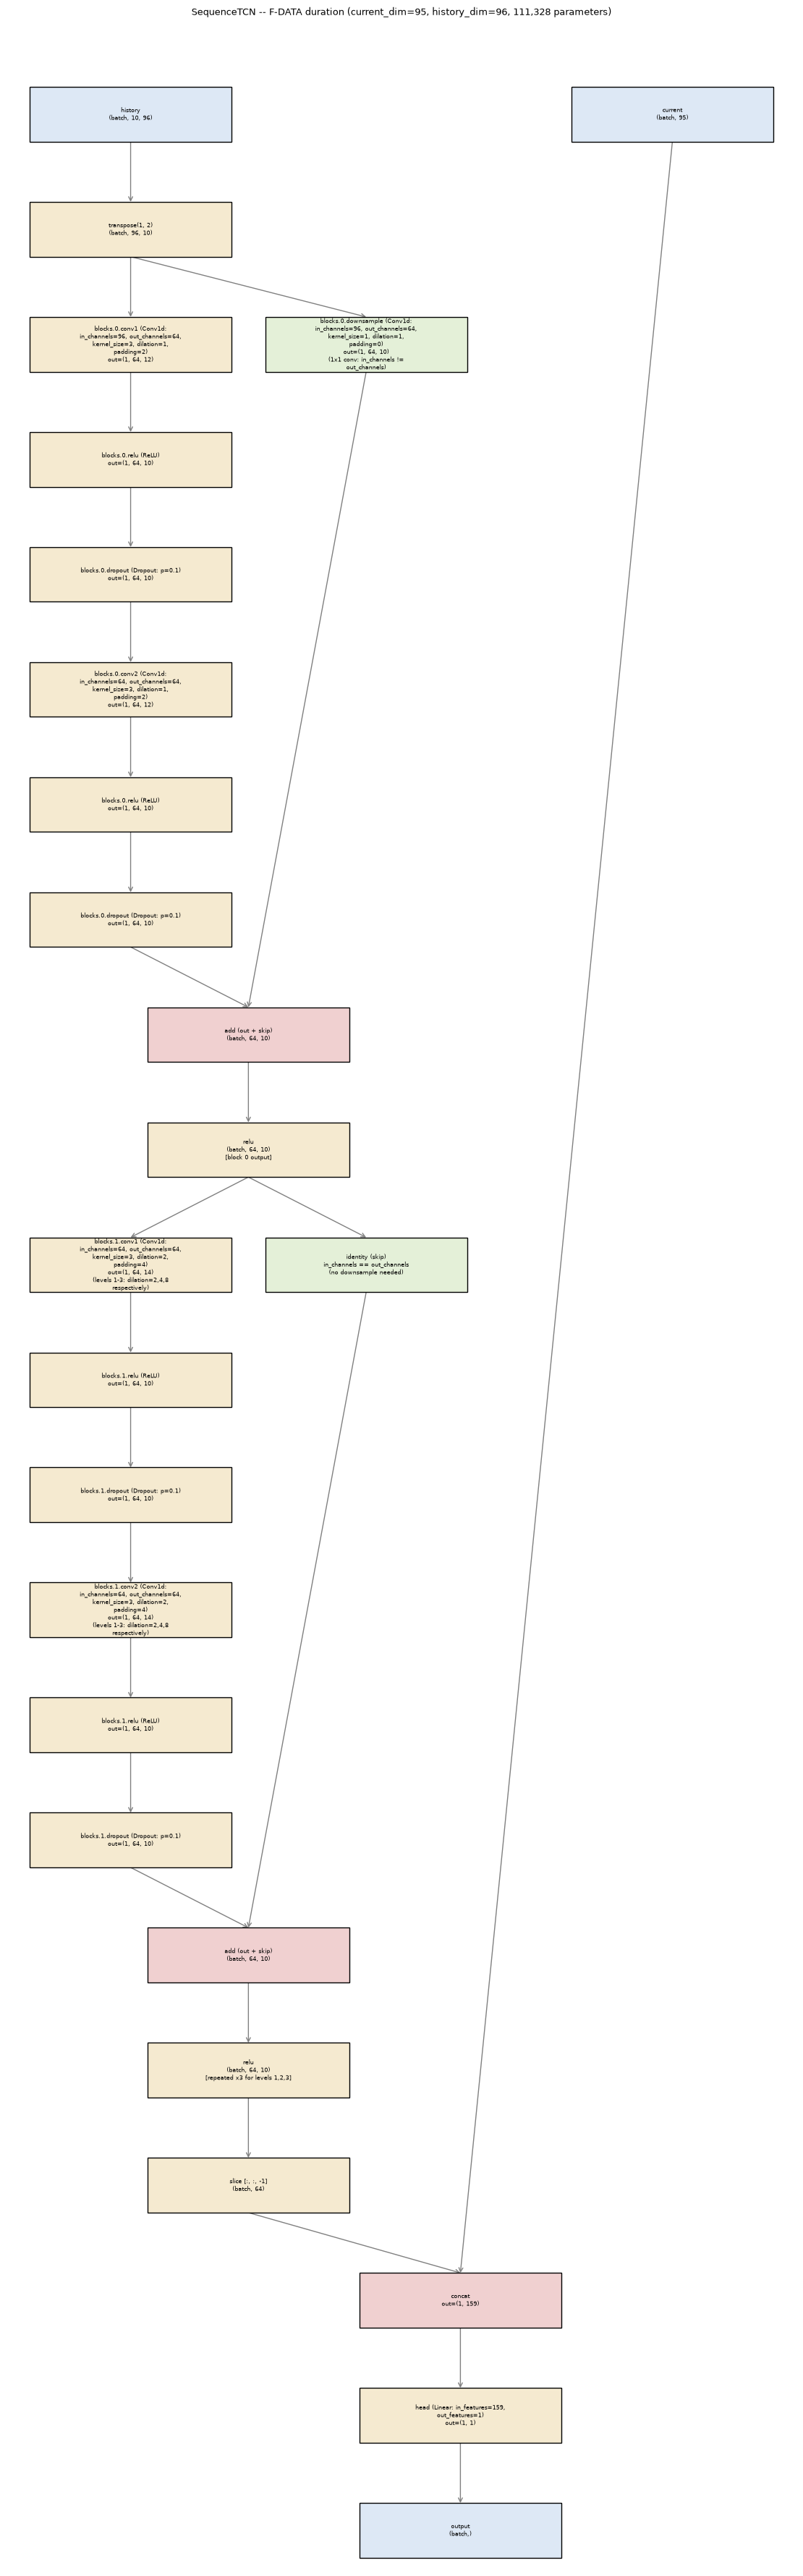

In [20]:
for dim in sorted(int(d) for d in dim_df["current_dim"].unique()):
    combos_sharing = distinct_dims_with_combos[dim]
    dataset_label = "F-DATA" if combos_sharing[0].startswith("fdata") else "PM100"
    combos_text = "/".join(c.replace("fdata_", "").replace("pm100_", "").replace("_c4", "")
                            for c in combos_sharing)

    tcn_model = SequenceTCN(history_dim=dim + 1, current_dim=dim)
    recs = trace_model_list(tcn_model, torch.randn(1, 10, dim + 1), torch.randn(1, dim))
    total, _ = count_params(tcn_model)

    def lbl(name, call=0):
        r = recs[name][call]
        return r["label"] + f"\nout={r['out_shape']}"

    channels = recs["blocks.0.conv1"][0]["out_shape"][1]
    head_rec = recs["head"][0]

    nodes = {
        "hist_in": dict(x=0, y=0, kind="io", text=f"history\n(batch, 10, {dim + 1})"),
        "cur_in": dict(x=2.3, y=0, kind="io", text=f"current\n(batch, {dim})"),
        "transpose": dict(x=0, y=1, kind="op",
                           text=f"transpose(1, 2)\n(batch, {dim + 1}, 10)"),

        # block 0 -- full detail, downsample skip (in_channels != out_channels)
        "b0_conv1": dict(x=0, y=2, kind="op", text=lbl("blocks.0.conv1")),
        "b0_relu1": dict(x=0, y=3, kind="op", text=lbl("blocks.0.relu", 0)),
        "b0_drop1": dict(x=0, y=4, kind="op", text=lbl("blocks.0.dropout", 0)),
        "b0_conv2": dict(x=0, y=5, kind="op", text=lbl("blocks.0.conv2")),
        "b0_relu2": dict(x=0, y=6, kind="op", text=lbl("blocks.0.relu", 1)),
        "b0_drop2": dict(x=0, y=7, kind="op", text=lbl("blocks.0.dropout", 1)),
        "b0_downsample": dict(x=1, y=2, kind="skip", text=lbl("blocks.0.downsample")
                               + "\n(1x1 conv: in_channels != out_channels)"),
        "b0_add": dict(x=0.5, y=8, kind="merge", text=f"add (out + skip)\n(batch, {channels}, 10)"),
        "b0_relu_out": dict(x=0.5, y=9, kind="op",
                             text=f"relu\n(batch, {channels}, 10)\n[block 0 output]"),

        # repeated block (levels 1,2,3 -- identical structure to each other, only dilation
        # differs: confirmed directly, same in/out channel count and kernel size for all
        # three -- shown ONCE, not three times
        "rep_conv1": dict(x=0, y=10, kind="op",
                           text=lbl("blocks.1.conv1") + "\n(levels 1-3: dilation=2,4,8 respectively)"),
        "rep_relu1": dict(x=0, y=11, kind="op", text=lbl("blocks.1.relu", 0)),
        "rep_drop1": dict(x=0, y=12, kind="op", text=lbl("blocks.1.dropout", 0)),
        "rep_conv2": dict(x=0, y=13, kind="op",
                           text=lbl("blocks.1.conv2") + "\n(levels 1-3: dilation=2,4,8 respectively)"),
        "rep_relu2": dict(x=0, y=14, kind="op", text=lbl("blocks.1.relu", 1)),
        "rep_drop2": dict(x=0, y=15, kind="op", text=lbl("blocks.1.dropout", 1)),
        "rep_identity": dict(x=1, y=10, kind="skip",
                              text="identity (skip)\nin_channels == out_channels\n(no downsample needed)"),
        "rep_add": dict(x=0.5, y=16, kind="merge", text=f"add (out + skip)\n(batch, {channels}, 10)"),
        "rep_relu_out": dict(x=0.5, y=17, kind="op",
                              text=f"relu\n(batch, {channels}, 10)\n[repeated x3 for levels 1,2,3]"),

        "slice": dict(x=0.5, y=18, kind="op", text=f"slice [:, :, -1]\n(batch, {channels})"),
        "concat": dict(x=1.4, y=19, kind="merge", text=f"concat\nout={head_rec['in_shapes'][0]}"),
        "head": dict(x=1.4, y=20, kind="op", text=head_rec["label"] + f"\nout={head_rec['out_shape']}"),
        "out": dict(x=1.4, y=21, kind="io", text="output\n(batch,)"),
    }
    edges = [
        ("hist_in", "transpose"),
        ("transpose", "b0_conv1"), ("b0_conv1", "b0_relu1"), ("b0_relu1", "b0_drop1"),
        ("b0_drop1", "b0_conv2"), ("b0_conv2", "b0_relu2"), ("b0_relu2", "b0_drop2"),
        ("b0_drop2", "b0_add"),
        ("transpose", "b0_downsample"), ("b0_downsample", "b0_add"),
        ("b0_add", "b0_relu_out"),

        ("b0_relu_out", "rep_conv1"), ("rep_conv1", "rep_relu1"), ("rep_relu1", "rep_drop1"),
        ("rep_drop1", "rep_conv2"), ("rep_conv2", "rep_relu2"), ("rep_relu2", "rep_drop2"),
        ("rep_drop2", "rep_add"),
        ("b0_relu_out", "rep_identity"), ("rep_identity", "rep_add"),
        ("rep_add", "rep_relu_out"),

        ("rep_relu_out", "slice"), ("slice", "concat"),
        ("cur_in", "concat"), ("concat", "head"), ("head", "out"),
    ]

    title = (f"SequenceTCN -- {dataset_label} {combos_text} (current_dim={dim}, "
             f"history_dim={dim + 1}, {total:,} parameters)")
    save_path = FIGURES_DIR / f"notebook06_arch_TCN_{dataset_label.lower()}_dim{dim}.png"
    draw_branching_diagram(nodes, edges, title, save_path)


## Training configuration

Read directly from `scripts/notebook06_deep_learning/run_sweep_pair.py` (the script that originally ran the sweep) and `src/dl_pipeline.py`'s own constants (`MAX_EPOCHS`, `PATIENCE`, `BATCH_SIZE`), not from memory.

In [21]:
config_rows = [
    dict(setting="Searched: learning rate", value="Optuna, log-uniform, 1e-5 to 1e-3, 10 trials"),
    dict(setting="Optimizer", value="Adam"),
    dict(setting="Loss", value="MSE (mean squared error), on the log-space target"),
    dict(setting="Batch size", value=BATCH_SIZE),
    dict(setting="Max epochs per trial", value=MAX_EPOCHS),
    dict(setting="Early-stopping patience", value=PATIENCE),
    dict(setting="Gradient clipping", value="clip_grad_norm_, max_norm=1.0"),
    dict(setting="tune_train / tune_val split", value="80% / 20%, chronological, within each combination's own train split"),
    dict(setting="Random seed", value="none set -- no torch.manual_seed() call anywhere in the sweep script; model weight init and DataLoader shuffling are NOT seeded. The ledger's seed=0 column is a schema label only, not an actual fixed seed."),
    dict(setting="FNN hidden sizes", value="256, 256, 128 (fixed)"),
    dict(setting="LSTM hidden size / layers", value="128 / 2 (fixed)"),
    dict(setting="TCN channels / levels / kernel", value="64 / 4 / 3 (fixed)"),
]
display(pd.DataFrame(config_rows).set_index("setting"))


,value
setting,
Searched: learning rate,"Optuna, log-uniform, 1e-5 to 1e-3, 10 trials"
Optimizer,Adam
Loss,"MSE (mean squared error), on the log-space target"
Batch size,4096
Max epochs per trial,20
Early-stopping patience,5
Gradient clipping,"clip_grad_norm_, max_norm=1.0"
tune_train / tune_val split,"80% / 20%, chronological, within each combinat..."
Random seed,none set -- no torch.manual_seed() call anywhe...


Architecture width and depth (FNN's hidden sizes, LSTM's hidden size and layer count, TCN's channel width, level count, and kernel size) were fixed by compute budget, not searched -- the only Optuna search dimension across all 18 pairs is the learning rate.

## Provable match between the documentation above and the real sweep

Loads EVERY one of the 18 (combination, architecture) pairs' own saved checkpoints from `data/interim/notebook06_sweep_models/` -- not just one combination -- and asserts each one's `state_dict` keys and tensor shapes match exactly what this notebook's own `FNN`/`SequenceLSTM`/`SequenceTCN` classes construct for that combination's own `current_dim`. If any of this ever failed, the documentation above would be describing a DIFFERENT model than the one actually trained for that pair.

In [22]:
def build_model_local(arch, current_dim, history_dim=None):
    """Local to this notebook -- dispatches to the notebook's OWN classes (not
    src.dl_pipeline.build_model, which uses src.models), so this check tests exactly what
    the documentation above describes."""
    if arch == "FNN":
        return FNN(current_dim)
    elif arch == "LSTM":
        return SequenceLSTM(history_dim, current_dim)
    else:
        return SequenceTCN(history_dim, current_dim)


all_pairs_checkpoint_rows = []
all_pairs_checked = 0
for combo in dim_df.index:
    combo_dim = int(dim_df.loc[combo, "current_dim"])
    for arch in ["FNN", "LSTM", "TCN"]:
        ckpt_path = CKPT_DIR / f"{combo}_{arch}_best.pt"
        ckpt_state = torch.load(ckpt_path, map_location="cpu")
        live_model = build_model_local(arch, combo_dim, combo_dim + 1)
        live_state = live_model.state_dict()

        keys_match = set(ckpt_state.keys()) == set(live_state.keys())
        shape_mismatches = [k for k in live_state if ckpt_state[k].shape != live_state[k].shape]
        assert keys_match, f"{combo}/{arch}: checkpoint keys do not match build_model_local()'s keys"
        assert not shape_mismatches, f"{combo}/{arch}: shape mismatches on {shape_mismatches}"

        live_total, _ = count_params(live_model)
        ckpt_total = sum(t.numel() for t in ckpt_state.values())
        assert live_total == ckpt_total, (
            f"{combo}/{arch}: build_model_local() has {live_total:,} parameters, "
            f"checkpoint has {ckpt_total:,}")

        all_pairs_checked += 1
        all_pairs_checkpoint_rows.append(dict(combo=combo, arch=arch, current_dim=combo_dim,
                                                n_tensors=len(ckpt_state), total_params=live_total,
                                                keys_match=keys_match,
                                                shape_mismatches=len(shape_mismatches)))

print(f"Checked {all_pairs_checked} (combination, architecture) pairs -- all 18 expected, "
      f"all passed (keys_match=True, shape_mismatches=0 on every row).")
display(pd.DataFrame(all_pairs_checkpoint_rows).set_index(["combo", "arch"]))


Checked 18 (combination, architecture) pairs -- all 18 expected, all passed (keys_match=True, shape_mismatches=0 on every row).


current_dim  n_tensors  total_params  keys_match  shape_mismatches
combo           arch                                                                    
fdata_power     FNN            93          8        122881        True                 0
                LSTM           93         10        247006        True                 0
                TCN            93         20        110814        True                 0
fdata_duration  FNN            95          8        123393        True                 0
                LSTM           95         10        248032        True                 0
                TCN            95         20        111328        True                 0
fdata_memory    FNN            93          8        122881        True                 0
                LSTM           93         10        247006        True                 0
                TCN            93         20        110814        True                 0
pm100_power     FNN            28          8        106241        True                 0
                LSTM           28         10        213661        True                 0
                TCN            28         20         94109        True                 0
pm100_duration  FNN            28          8        106241        True                 0
                LSTM           28         10        213661        True                 0
                TCN            28         20         94109        True                 0
pm100_memory_c4 FNN            22          8        104705        True                 0
                LSTM           22         10        210583        True                 0
                TCN            22         20         92567        True                 0

The table above shows the real result of running that same checkpoint-match assertion on all 18 pairs, not an implicit claim that it would pass -- every row shows `keys_match=True` and `shape_mismatches=0`, confirmed by the real `assert` statements in the cell above (which would have raised on the first pair to fail, not silently continued). The models documented in this notebook are provably the same objects the sweep trained and notebooks 06c/06d/06e evaluate, for every one of the six combinations and three architectures, not just the one example used to build the documentation.